# Data Exploration, Quality Audit & Preprocessing


**COS30082 Applied Machine Learning, Assignment 1** · Ling Zhi An (102786768)

## 0. Setup

The notebook runs on a laptop CPU in about a minute; no GPU is needed. It reads the unpacked images in `data/cub/` (from the assignment's `Train.zip`, `Test.zip`, `train.txt` and `test.txt`), the audit files in `metadata/` written by `scripts/prepare_data.py` and `scripts/audit_embeddings.py`, and the final model's training configuration in `results/run_logs/`.

In [1]:
# Import libraries
import json
import platform
import random
import warnings
from collections import Counter, defaultdict
from io import BytesIO
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import timm
import torch
import torchvision
from IPython.display import Image as JpegImage
from IPython.display import Markdown, display
from PIL import Image, ImageDraw
from timm.data import Mixup
from torch.utils.data import DataLoader
from torchvision import transforms as T
from torchvision.transforms import autoaugment

from birdcls.audit import dhash, file_md5, flagged_test_images, group_exact_duplicates, near_duplicate_pairs
from birdcls.config import TrainConfig
from birdcls.data import (BirdDataset, build_eval_transform, build_train_transform, derive_class_names,
                          load_splits, load_val_split, stratified_holdout)

# The repository root, whether the kernel starts in notebooks/ or at the root.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
DATA, META, RUN_LOGS = REPO / "data" / "cub", REPO / "metadata", REPO / "results" / "run_logs"
FINAL_RUN = "convnext_l_inat21_448"  # the training run of the deployed ConvNeXt-L
BASE_MODEL = REPO / "app" / "bundle" / "base_model" / "config.json"  # the backbone's hub config

# Check the input files
needed = [DATA / "train.txt", DATA / "test.txt", DATA / "Train", DATA / "Test", META / "audit.json",
          RUN_LOGS / FINAL_RUN / "config.json", BASE_MODEL]
missing = [str(p.relative_to(REPO)) for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError(f"missing {missing}: unpack the assignment data with scripts/prepare_data.py")

# One seed for every random draw, so a re-run shows the same photos and the same augmentations.
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set plot style and colors
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6,
    "legend.frameon": False,
})
FIT, VAL, TEST, ACCENT, GRAY = "#2f6b9a", "#e1a03b", "#7a9a3a", "#c0504d", "#9a9a9a"


# Define helpers
def show_jpeg(fig: plt.Figure, quality: int = 80) -> None:
    """Display a photo-heavy figure as a JPEG, a tenth of the PNG size, so the saved notebook stays small."""
    buffer = BytesIO()
    fig.savefig(buffer, format="jpeg", dpi=fig.dpi, bbox_inches="tight", pil_kwargs={"quality": quality})
    plt.close(fig)
    display(JpegImage(buffer.getvalue()))


def square(path: Path, size: int = 160) -> Image.Image:
    """The center square of a photo (the part the evaluation transform keeps), as a thumbnail."""
    with Image.open(path) as im:
        im = im.convert("RGB")
    side = min(im.size)
    left, top = (im.width - side) // 2, (im.height - side) // 2
    return im.crop((left, top, left + side, top + side)).resize((size, size), Image.Resampling.BICUBIC)


def md_table(header: list[str], rows: list[list]) -> None:
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


# Print versions
print(f"Python {platform.python_version()} · torch {torch.__version__} · torchvision {torchvision.__version__} · "
      f"timm {timm.__version__} · numpy {np.__version__} · matplotlib {matplotlib.__version__}")
print(f"repository: {REPO.name}, images: {DATA.relative_to(REPO)}")

Python 3.14.3 · torch 2.14.0 · torchvision 0.29.0 · timm 1.0.30 · numpy 2.5.3 · matplotlib 3.11.2
repository: AML Assignment, images: data/cub


## 1. The dataset at a glance

### 1.1 The annotation files

Each annotation file has one `<file name> <label>` line per photo. `birdcls.data.load_splits` parses both into `Sample` records (file name, integer label, image folder).

In [2]:
# Load splits
train, test = load_splits(DATA)

# Print the first lines and the label range
for name in ("train.txt", "test.txt"):
    print(f"{name}:", *(DATA / name).read_text().splitlines()[:3], "...", sep="\n    ")
print(f"\n{len(train):,} training photos and {len(test):,} test photos, "
      f"labels {min(s.label for s in train)}–{max(s.label for s in train)}")
test_in_train = {s.label for s in test} <= {s.label for s in train}
print(f"every test label also appears in training: {test_in_train}")

train.txt:
    Black_footed_Albatross_0004_2731401028.jpg 0
    Black_footed_Albatross_0008_1384283201.jpg 0
    Black_footed_Albatross_0011_820118444.jpg 0
    ...
test.txt:
    0000.jpg 0
    0001.jpg 0
    0002.jpg 0
    ...

4,829 training photos and 1,204 test photos, labels 0–199
every test label also appears in training: True


The training file names carry the species name (`Black_footed_Albatross_0019_…`), but the test files are anonymous (`0000.jpg`), so the training names are the only source of class names. `derive_class_names` recovers one name per label and fails loudly if a label ever maps to two species, which would expose a corrupted annotation file.

### 1.2 The 200 species and how they group

200 species in 70 groups by the last word of the name; 167 species (84%) share their group with at least one other species, in 37 groups


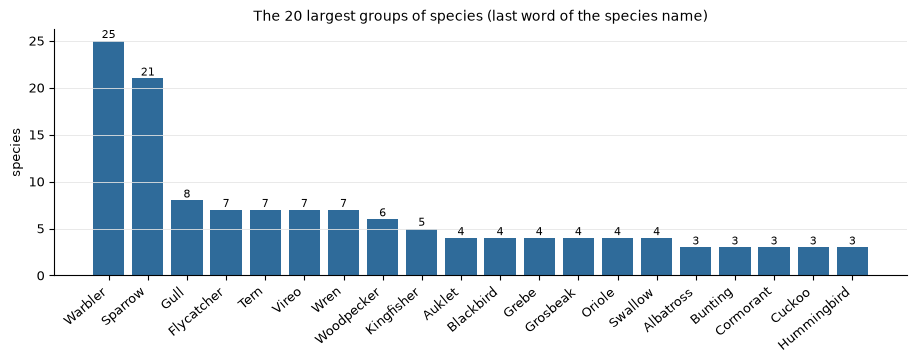

In [3]:
# Get class names and groups
classes = derive_class_names(train)
assert classes == json.loads((META / "classes.json").read_text()), "metadata/classes.json is out of date"
group_of = [name.split()[-1] for name in classes]  # the last word names the kind of bird: "... Warbler"
groups = Counter(group_of)
shared = {g: n for g, n in groups.items() if n > 1}
print(f"{len(classes)} species in {len(groups)} groups by the last word of the name; "
      f"{sum(shared.values())} species ({sum(shared.values()) / len(classes):.0%}) share their group with at "
      f"least one other species, in {len(shared)} groups")

# Draw the 20 largest groups
top = groups.most_common(20)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar([g for g, _ in top], [n for _, n in top], color=FIT)

# Label bars with counts
for i, (_, n) in enumerate(top):
    ax.text(i, n + 0.3, str(n), ha="center", fontsize=8)

# Set labels and show
ax.set(ylabel="species", title="The 20 largest groups of species (last word of the species name)")
ax.grid(axis="x", visible=False)
plt.xticks(rotation=40, ha="right")
plt.show()

The last word of a name is a rough grouping, not a taxonomy: it puts the Chuck-will's-widow under "Widow" and the genus-level class *Sayornis* in a group of its own. It still shows the shape of the problem. 167 of the 200 species (84 %) share their group with at least one other species, and the two largest groups, 25 warblers and 21 sparrows, hold almost a quarter of all classes. The hard part of the task is telling a species from its group-mates, not a gull from a duck.

→ **Decision:** Notebook 2 uses these groups to test whether the errors stay inside a group (sections 9.5 and 9.6).

### 1.3 One photo of every species

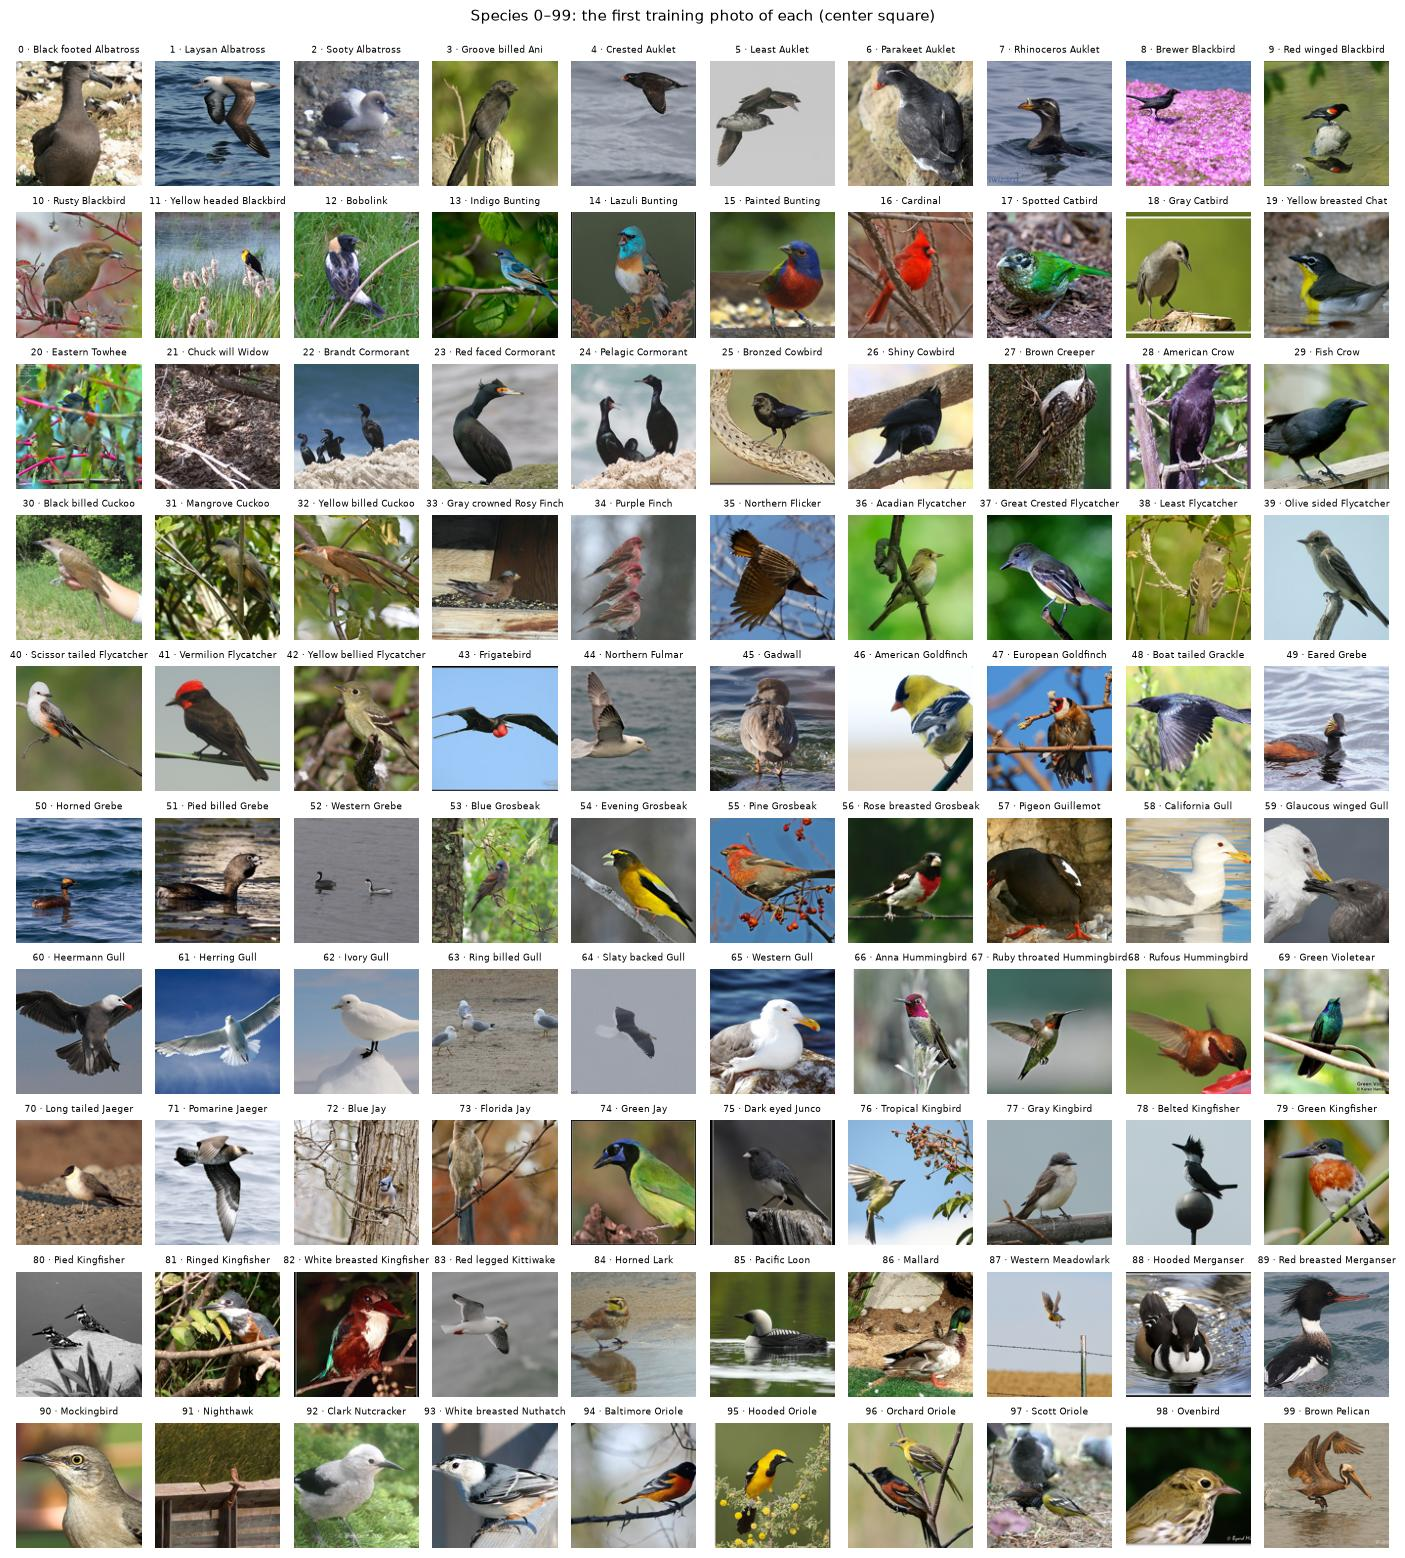

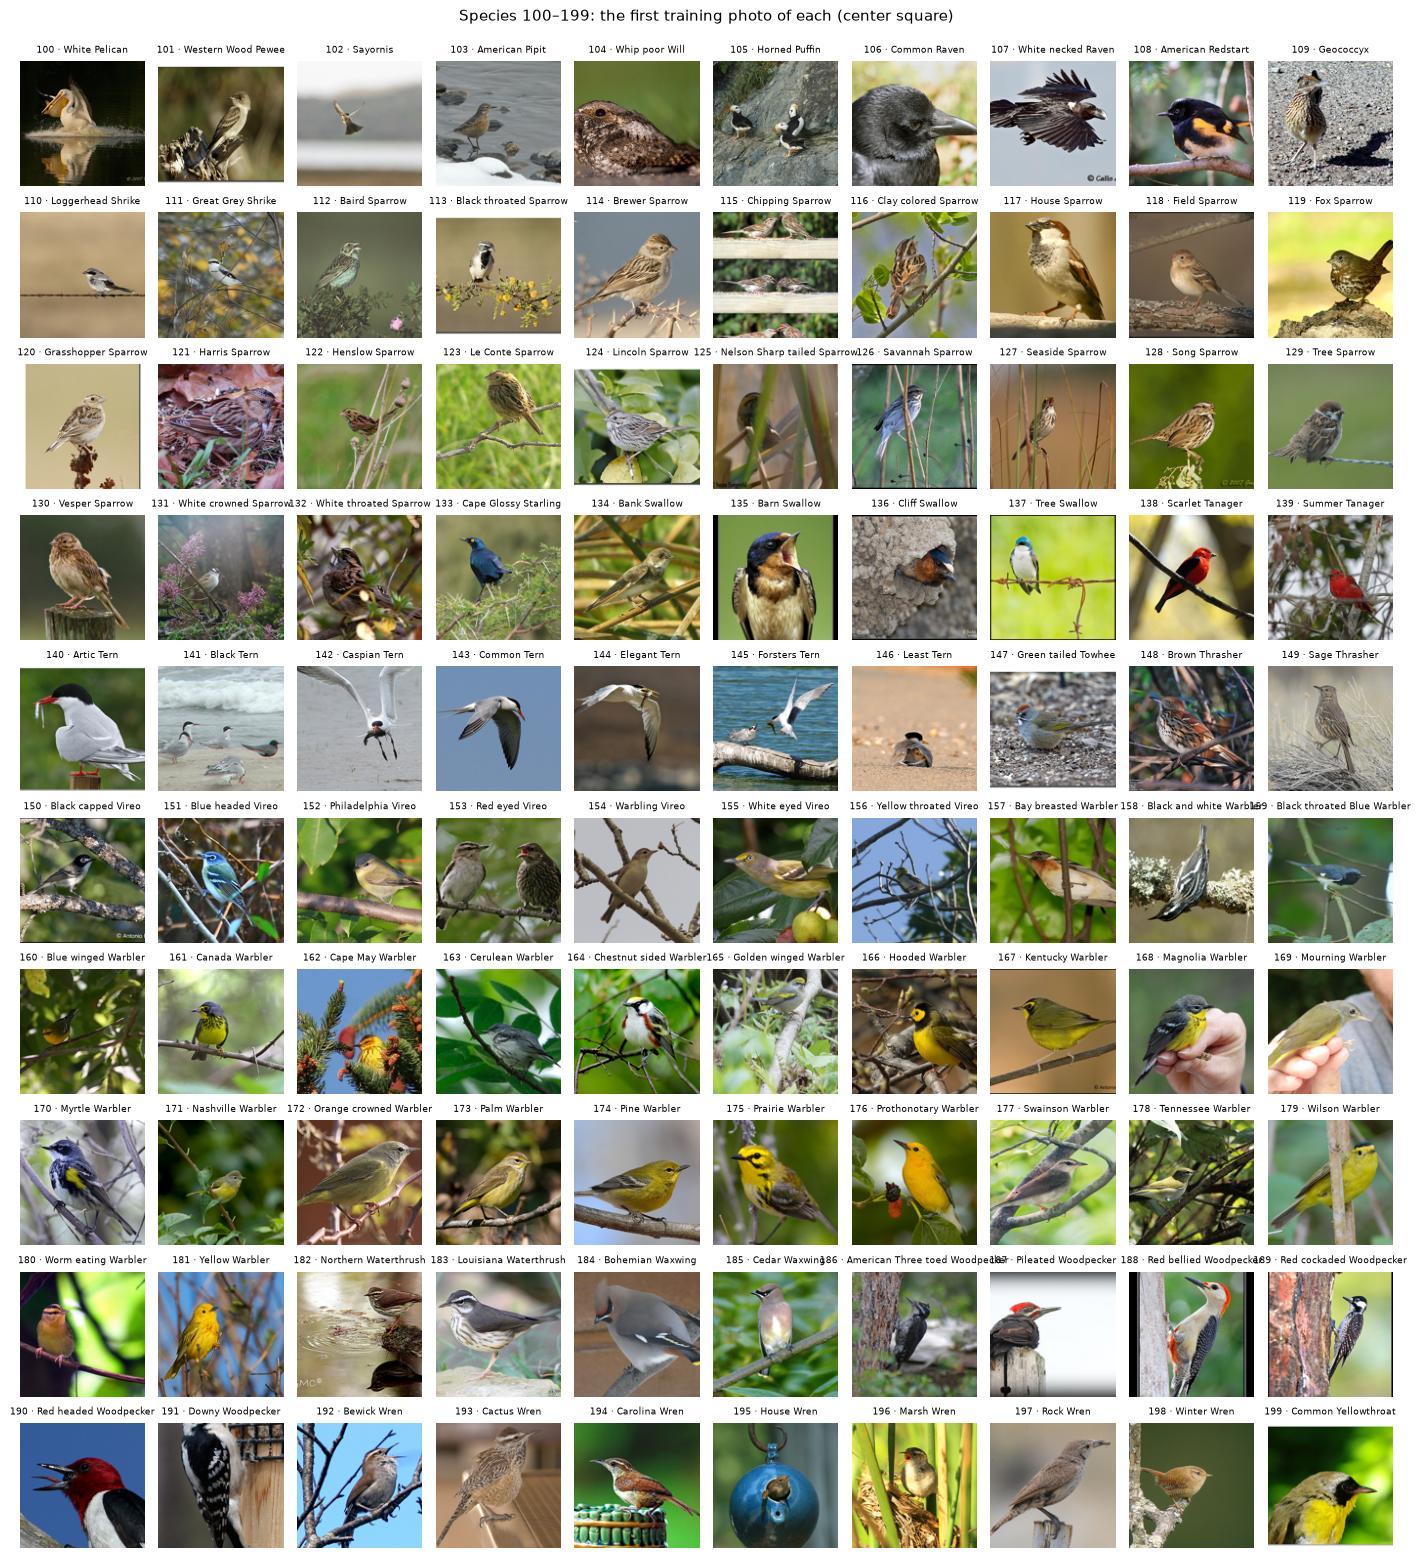

In [4]:
# Pick the first photo of each species
first_photo = {}
for s in sorted(train, key=lambda s: s.filename):
    first_photo.setdefault(s.label, s)

# Draw two mosaics of 100 species
for start in (0, 100):
    fig, axes = plt.subplots(10, 10, figsize=(14, 15.6))
    # Draw one photo per species
    for ax, label in zip(axes.flat, range(start, start + 100)):
        ax.imshow(square(first_photo[label].path(DATA), 128))
        ax.set_title(f"{label} · {classes[label]}", fontsize=6.3)
        ax.axis("off")

    # Add title and show
    fig.suptitle(f"Species {start}–{start + 99}: the first training photo of each (center square)", y=0.997)
    fig.tight_layout()
    show_jpeg(fig, quality=75)

The mosaic shows how varied the framing is. Some birds fill the frame (Mockingbird, Ovenbird); others are a few pixels wide (the Western Meadowlark in flight, the Nighthawk on a fence) or hidden (the Eastern Towhee in foliage, the camouflaged Chuck-will's-widow on leaf litter). Some photos show several birds (the Brandt's Cormorant flock), one is grayscale (Pied Kingfisher), and one shows a bird held in a hand (Black-billed Cuckoo). The background also follows the kind of bird: seabirds on water, songbirds in foliage. A classifier could exploit that as a shortcut instead of looking at the bird.

→ **Decision:** random crops at varying scale during training (section 6.2), and Grad-CAM in Notebook 2 (sections 10 and 11) to check where the model looks.

## 2. Class balance and the validation split

### 2.1 Photos per species

| file | photos | min per species | median | mean | max | max / min |
|---|---|---|---|---|---|---|
| train.txt | 4,829 | 16 | 25 | 24.1 | 31 | 1.9 |
| test.txt | 1,204 | 4 | 6 | 6.0 | 8 | 2.0 |

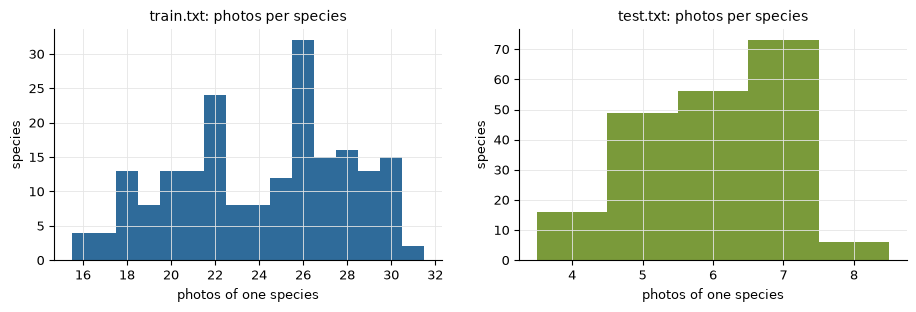

test photos per training photo: 0.22–0.28 per species (overall 0.25); correlation of the two counts: 0.94


In [5]:
# Count photos per species
train_counts = np.bincount([s.label for s in train], minlength=len(classes))
test_counts = np.bincount([s.label for s in test], minlength=len(classes))
audit = json.loads((META / "audit.json").read_text())
assert train_counts.min() == audit["train_images_per_class"]["min"]
assert test_counts.max() == audit["test_images_per_class"]["max"]

# Show count statistics
md_table(["file", "photos", "min per species", "median", "mean", "max", "max / min"], [
    [name, f"{counts.sum():,}", counts.min(), int(np.median(counts)), f"{counts.mean():.1f}", counts.max(),
     f"{counts.max() / counts.min():.1f}"]
    for name, counts in (("train.txt", train_counts), ("test.txt", test_counts))])

# Draw photos per species
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, counts, color, name in ((axes[0], train_counts, FIT, "train.txt"), (axes[1], test_counts, TEST, "test.txt")):
    ax.hist(counts, bins=np.arange(counts.min() - 0.5, counts.max() + 1.5), color=color)
    ax.set(title=f"{name}: photos per species", xlabel="photos of one species", ylabel="species")
plt.show()

# Print test-to-train ratio
ratio = test_counts / train_counts
print(f"test photos per training photo: {ratio.min():.2f}–{ratio.max():.2f} per species "
      f"(overall {len(test) / len(train):.2f}); correlation of the two counts: "
      f"{np.corrcoef(train_counts, test_counts)[0, 1]:.2f}")

The classes are mildly imbalanced: the largest species has 1.9 times the training photos of the smallest. The test set is a near-constant quarter of each species' training count (0.22–0.28, correlation 0.94), so it was drawn as a fixed share per species and has the same class distribution as training. With so little imbalance, top-1 accuracy and the average per-class accuracy can differ only slightly (the final model scores 96.6 % on both).

→ **Decision:** plain cross-entropy without class weights or resampling; both required metrics are reported.

### 2.2 The validation split

Hyper-parameters, checkpoints, calibration and ensembles are all chosen on a validation split carved out of `train.txt`; the test set is only scored at the end. `stratified_holdout` takes 20 % of every species separately, so every class keeps several validation photos. The split is drawn once and committed as `metadata/val_split.json`; the cell below re-draws it from its recorded seed and checks that it gives exactly the committed file list.

fit 3,870 · val 959 · test 1,204: re-drawn from seed 20260926, identical to metadata/val_split.json


| split | photos | min per species | median | max | species present |
|---|---|---|---|---|---|
| fit (trains the weights) | 3,870 | 13 | 20 | 25 | 200 |
| val (chooses settings) | 959 | 3 | 5 | 6 | 200 |
| test (final score only) | 1,204 | 4 | 6 | 8 | 200 |

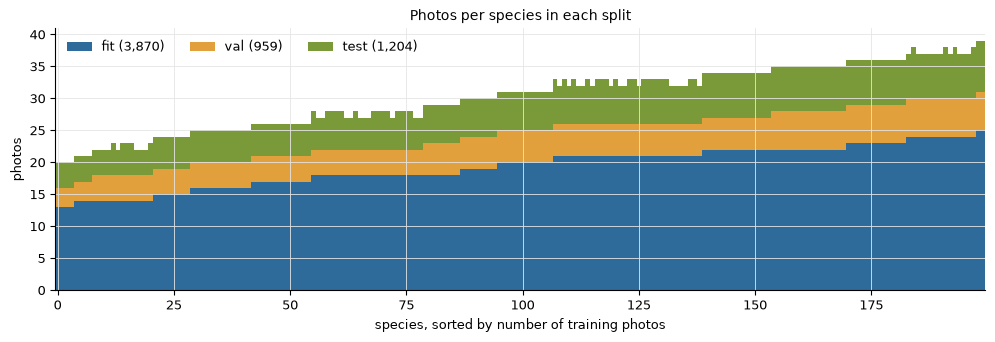

In [6]:
# Load the validation split
split = json.loads((META / "val_split.json").read_text())
fit, val, test_split = load_val_split(DATA, META / "val_split.json")
assert [s.filename for s in test_split] == [s.filename for s in test]

# Redraw the split and check it matches
redrawn_fit, redrawn_val = stratified_holdout(train, split["fraction"], split["seed"])
assert sorted(s.filename for s in redrawn_val) == sorted(split["val"])
assert {s.filename for s in redrawn_fit} == {s.filename for s in fit}
print(f"fit {len(fit):,} · val {len(val):,} · test {len(test):,}: "
      f"re-drawn from seed {split['seed']}, identical to metadata/val_split.json")

# Count photos per split
fit_counts = np.bincount([s.label for s in fit], minlength=len(classes))
val_counts = np.bincount([s.label for s in val], minlength=len(classes))
md_table(["split", "photos", "min per species", "median", "max", "species present"], [
    [name, f"{c.sum():,}", c.min(), int(np.median(c)), c.max(), int((c > 0).sum())]
    for name, c in (("fit (trains the weights)", fit_counts), ("val (chooses settings)", val_counts),
                    ("test (final score only)", test_counts))])

# Draw photos per species in each split
order = np.argsort(train_counts, kind="stable")
x = np.arange(len(classes))
fig, ax = plt.subplots(figsize=(12, 3.4))

# Stack fit, val and test bars
ax.bar(x, fit_counts[order], width=1.0, color=FIT, label=f"fit ({len(fit):,})")
ax.bar(x, val_counts[order], width=1.0, bottom=fit_counts[order], color=VAL, label=f"val ({len(val):,})")
ax.bar(x, test_counts[order], width=1.0, bottom=(fit_counts + val_counts)[order], color=TEST,
       label=f"test ({len(test):,})")

# Set labels and legend
ax.set(xlim=(-0.5, len(classes) - 0.5), xlabel="species, sorted by number of training photos", ylabel="photos",
       title="Photos per species in each split")
ax.legend(ncol=3, loc="upper left")
plt.show()

Each species keeps 3–6 validation photos (median 5) and 13–25 fit photos (median 20). With 959 val photos, one photo is worth 0.10 percentage points (pp) of val accuracy. A difference of 0.3 pp between two settings is therefore three photos, which a different random seed can produce on its own.

→ **Decision:** the final recipe was trained with three seeds, and every ablation is read against their spread σ (Notebook 2, section 8.6) instead of as a single comparison. Models train on the fit split only. A model refitted on all 4,829 photos would gain 20 % more data, but its stopping epoch and temperature could no longer be checked on held-out photos.

## 3. Image properties

### 3.1 Size, shape and the model's input resolution

Opening a JPEG with PIL reads only its header, so the size and color mode of all 6,033 photos take a few seconds.

color modes: {'RGB': 6033}; width 162–500 px, height 121–500 px


| width × height | photos | share |
|---|---|---|
| 500 × 375 | 768 | 12.7% |
| 500 × 333 | 767 | 12.7% |
| 500 × 400 | 304 | 5.0% |
| 500 × 334 | 167 | 2.8% |
| 333 × 500 | 165 | 2.7% |
| 400 × 500 | 159 | 2.6% |

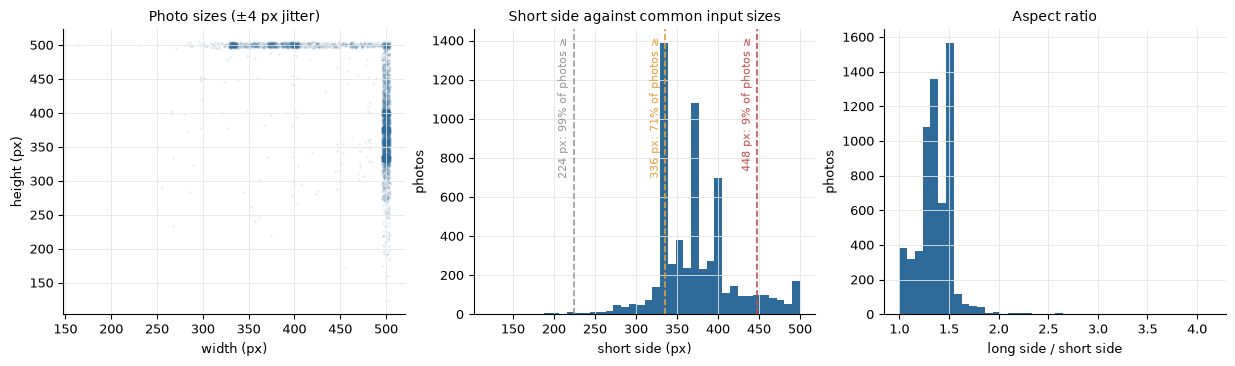

91.2% of photos have a short side below 448 px: the 448-px input upsamples them (median factor 1.19×, largest 3.7×)
the square center crop discards a median 25% of a photo's area (up to 76%); 36% of photos lose more than 30 %


In [7]:
# Read image sizes and modes
samples = train + test
sizes, modes = [], Counter()
for s in samples:
    with Image.open(s.path(DATA)) as im:
        sizes.append(im.size)
        modes[im.mode] += 1

# Get width, height and sides
sizes = np.array(sizes)
width, height = sizes[:, 0], sizes[:, 1]
short, long = np.minimum(width, height), np.maximum(width, height)
assert int(np.median(short)) == audit["short_side"]["median"]

# Print size summary
print(f"color modes: {dict(modes)}; width {width.min()}–{width.max()} px, height {height.min()}–{height.max()} px")
md_table(["width × height", "photos", "share"],
         [[f"{w} × {h}", f"{n:,}", f"{n / len(samples):.1%}"]
          for (w, h), n in Counter(map(tuple, sizes.tolist())).most_common(6)])

# Draw photo sizes
fig, axes = plt.subplots(1, 3, figsize=(15, 3.7))
jitter = np.random.default_rng(SEED).uniform(-4, 4, size=sizes.shape)
axes[0].scatter(width + jitter[:, 0], height + jitter[:, 1], s=3, alpha=0.12, color=FIT, linewidths=0)
axes[0].set(xlabel="width (px)", ylabel="height (px)", title="Photo sizes (±4 px jitter)")

# Draw short sides against input sizes
axes[1].hist(short, bins=40, color=FIT)
top_y = axes[1].get_ylim()[1]
for size, color in ((224, GRAY), (336, VAL), (448, ACCENT)):
    axes[1].axvline(size, color=color, linestyle="--", linewidth=1.2)
    axes[1].text(size - 6, 0.97 * top_y, f"{size} px: {np.mean(short >= size):.0%} of photos ≥", rotation=90,
                 ha="right", va="top", fontsize=8, color=color)
axes[1].set(xlabel="short side (px)", ylabel="photos", title="Short side against common input sizes")

# Draw aspect ratios
axes[2].hist(long / short, bins=40, color=FIT)
axes[2].set(xlabel="long side / short side", ylabel="photos", title="Aspect ratio")
plt.show()

# Print upsampling and crop losses
discarded = 1 - short / long
print(f"{np.mean(short < 448):.1%} of photos have a short side below 448 px: the 448-px input upsamples them "
      f"(median factor {np.median(448 / short):.2f}×, largest {np.max(448 / short):.1f}×)")
print(f"the square center crop discards a median {np.median(discarded):.0%} of a photo's area "
      f"(up to {discarded.max():.0%}); {np.mean(discarded > 0.3):.0%} of photos lose more than 30 %")

The dataset's photos were scaled to at most 500 px on each side; the two most common sizes are landscape 4:3 and 3:2 at 500 px wide. 99 % have a short side of at least 224 px, 71 % of at least 336 px, but only 9 % of at least 448 px. A 448 px input therefore enlarges 91 % of the photos (median 1.19×, at most 3.7×). Enlarging adds no detail, but it does keep every pixel, whereas a 224 px input would shrink the median photo to 60 % of its height. It also gives the ConvNeXt-L a 14 × 14 final feature map instead of 7 × 7. The backbone was trained on iNat21 at 384 px and is published with a 448 px test resolution.

The square center crop is the larger cost: it discards a median 25 % of each photo, up to 76 % for panoramas, and 36 % of photos lose more than 30 %.

→ **Decision:** input 448 px; the evaluation transform resizes the short side straight to 448 (`eval_crop_pct = 1.0`) instead of zooming in further, as the common ImageNet setting of 0.875 would. The sides that remain cut off are a known limitation; Notebook 2 (section 11) finds photos where the crop removed the labeled bird.

### 3.2 Color statistics and the normalization constants

The network subtracts a per-channel mean and divides by a standard deviation before the first layer. Those constants come from the backbone's pretraining (CLIP, for this ConvNeXt-L), not from CUB, because the pretrained filters expect inputs on that scale. The cell below measures CUB's own statistics on every photo to see how far they are from the constants used. `Image.draft` lets the JPEG decoder shrink each photo while decoding, which makes the pass over all 6,033 photos about ten times faster.

| statistics of | mean (R / G / B) | std (R / G / B) |
|---|---|---|
| CUB, all 6,033 photos (measured here) | 0.478 / 0.494 / 0.426 | 0.228 / 0.223 / 0.263 |
| ConvNeXt-L normalization (CLIP pretraining) | 0.481 / 0.458 / 0.408 | 0.269 / 0.261 / 0.276 |
| ImageNet normalization (ResNet-50) | 0.485 / 0.456 / 0.406 | 0.229 / 0.224 / 0.225 |

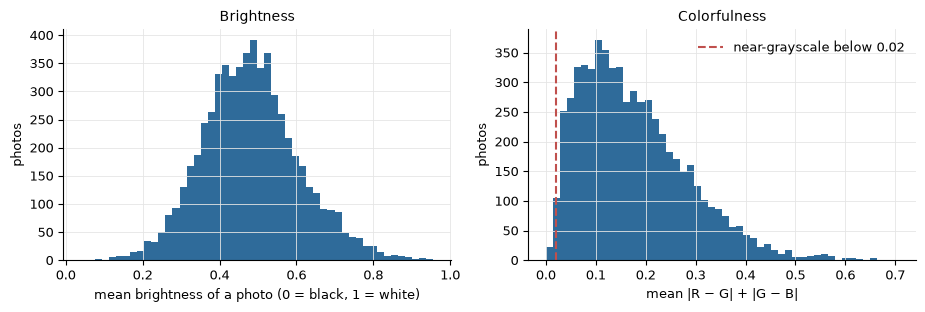

52 near-grayscale photos; darkest 0.04, brightest 0.96


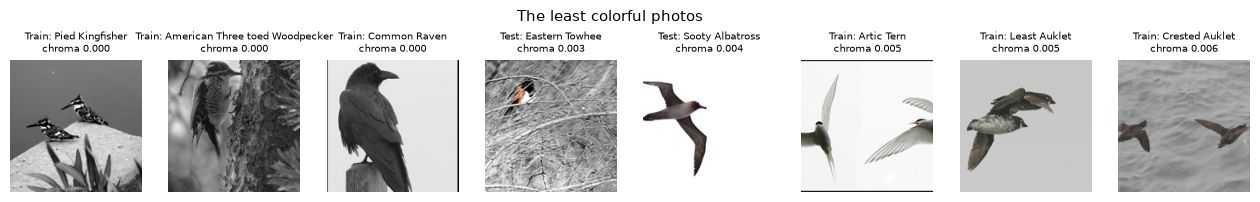

In [8]:
def color_stats(path: Path) -> tuple[np.ndarray, np.ndarray, float]:
    """Per-channel mean and mean square of one photo, plus its colorfulness (mean channel difference)."""
    with Image.open(path) as im:
        im.draft("RGB", (128, 128))
        pixels = np.asarray(im.convert("RGB").resize((128, 128)), dtype=np.float64).reshape(-1, 3) / 255
    chroma = np.abs(pixels[:, 0] - pixels[:, 1]).mean() + np.abs(pixels[:, 1] - pixels[:, 2]).mean()
    return pixels.mean(axis=0), (pixels ** 2).mean(axis=0), chroma


# Measure every photo
stats = [color_stats(s.path(DATA)) for s in samples]
means = np.array([m for m, _, _ in stats])
squares = np.array([q for _, q, _ in stats])
chroma = np.array([c for _, _, c in stats])
data_mean = means.mean(axis=0)
data_std = np.sqrt(squares.mean(axis=0) - data_mean ** 2)  # pooled over every pixel of every photo

# Load normalization constants
pretrained = json.loads(BASE_MODEL.read_text())["pretrained_cfg"]
MEAN, STD = pretrained["mean"], pretrained["std"]
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


# Format three channel values
def fmt(values) -> str:
    return " / ".join(f"{v:.3f}" for v in values)


# Compare with the pretraining constants
md_table(["statistics of", "mean (R / G / B)", "std (R / G / B)"], [
    ["CUB, all 6,033 photos (measured here)", fmt(data_mean), fmt(data_std)],
    ["ConvNeXt-L normalization (CLIP pretraining)", fmt(MEAN), fmt(STD)],
    ["ImageNet normalization (ResNet-50)", fmt(IMAGENET_MEAN), fmt(IMAGENET_STD)]])

# Compute brightness
luminance = means @ np.array([0.299, 0.587, 0.114])

# Draw brightness
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(luminance, bins=50, color=FIT)
axes[0].set(xlabel="mean brightness of a photo (0 = black, 1 = white)", ylabel="photos", title="Brightness")

# Draw colorfulness
axes[1].hist(chroma, bins=50, color=FIT)
axes[1].axvline(0.02, color=ACCENT, linestyle="--", label="near-grayscale below 0.02")
axes[1].set(xlabel="mean |R − G| + |G − B|", ylabel="photos", title="Colorfulness")
axes[1].legend()
plt.show()

# Show the least colorful photos
gray = np.flatnonzero(chroma < 0.02)
print(f"{len(gray)} near-grayscale photos; darkest {luminance.min():.2f}, brightest {luminance.max():.2f}")
if len(gray):
    shown = gray[np.argsort(chroma[gray])][:8]
    fig, axes = plt.subplots(1, len(shown), figsize=(2 * len(shown), 2.4), squeeze=False)
    for ax, i in zip(axes[0], shown):
        ax.imshow(square(samples[i].path(DATA), 160))
        ax.set_title(f"{samples[i].split}: {classes[samples[i].label]}\nchroma {chroma[i]:.3f}", fontsize=7)
        ax.axis("off")
    fig.suptitle("The least colorful photos")
    show_jpeg(fig)

CUB is close to the CLIP statistics the backbone was pretrained with. Its mean is slightly greener (G +0.036, about 0.14 standard deviations), from the foliage behind most songbirds. Its standard deviation is lower, so normalized CUB pixels have a spread of about 0.85–0.95 instead of 1. The ImageNet constants used by ResNet-50 are almost the same as CLIP's.

52 photos are near-grayscale. Several are exactly grayscale (chroma 0.000), and those happen to be black-and-white birds: Pied Kingfisher, American Three-toed Woodpecker, Common Raven. Brightness ranges from 0.04 (almost black) to 0.96 (overexposed).

→ **Decision:** keep the pretraining constants. The first layer's filters were learned on inputs normalized with them, and constants re-estimated on CUB would shift every input away from that. TrivialAugment's color operation, at its strongest negative setting, removes almost all color, so training occasionally sees near-grayscale versions of colorful species. No separate grayscale augmentation was added.

## 4. Why the task is hard

### 4.1 Look-alike species

Fine-grained classification means telling apart species that differ in small details: bill length, a wing bar, the color of the legs. The groups below are the species the final model most often confuses (Notebook 2, section 9.6); each row is one species, with four random training photos.

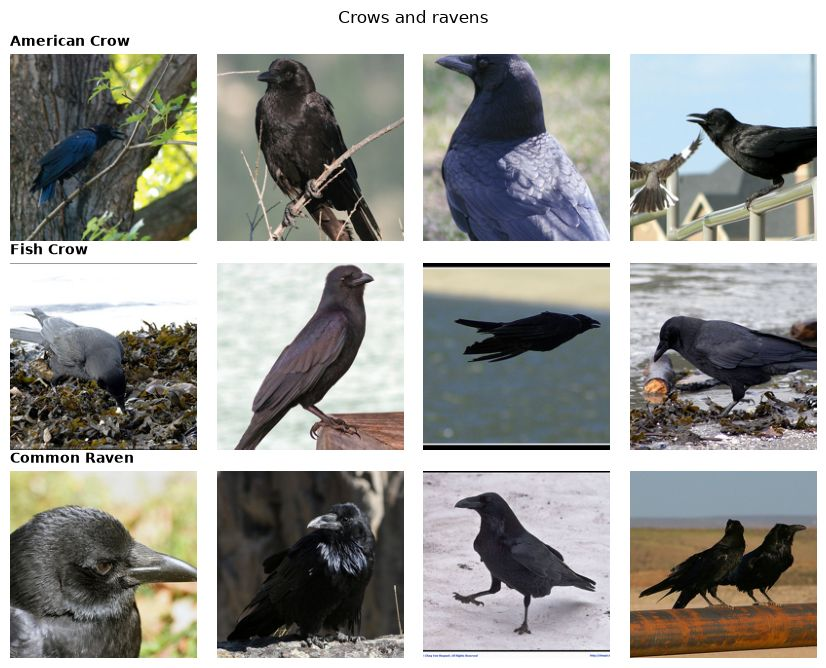

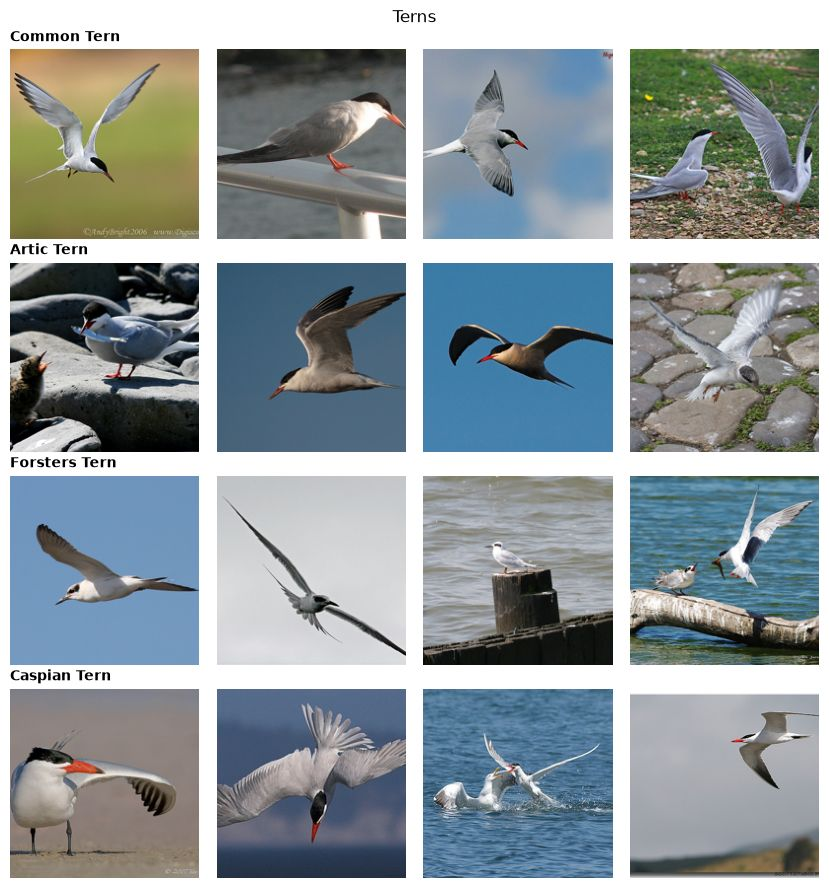

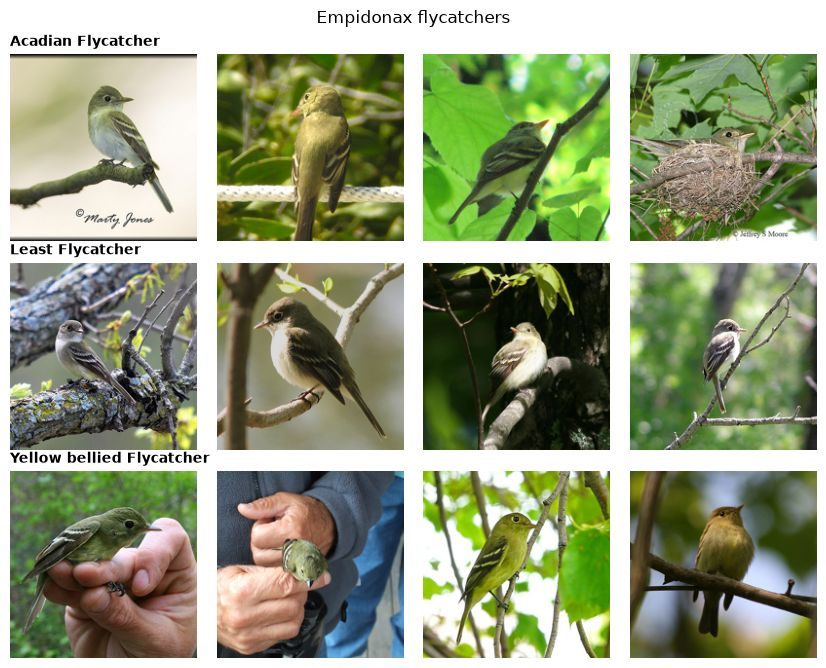

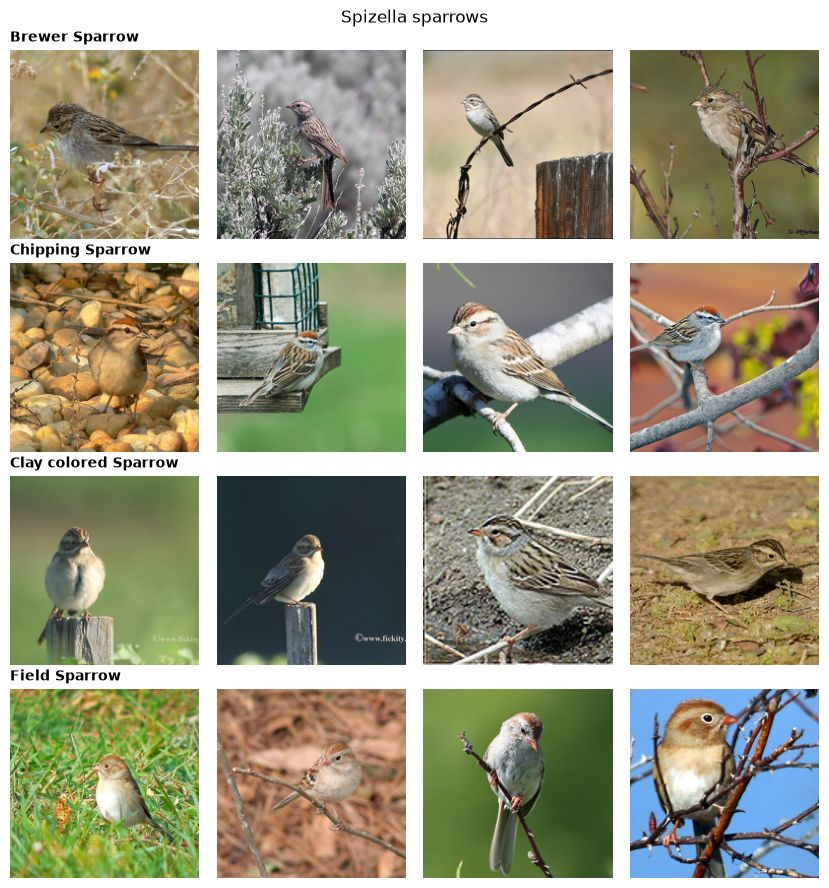

In [9]:
# Pick look-alike groups
LOOK_ALIKES = {
    "Crows and ravens": ["American Crow", "Fish Crow", "Common Raven"],
    "Terns": ["Common Tern", "Artic Tern", "Forsters Tern", "Caspian Tern"],
    "Empidonax flycatchers": ["Acadian Flycatcher", "Least Flycatcher", "Yellow bellied Flycatcher"],
    "Spizella sparrows": ["Brewer Sparrow", "Chipping Sparrow", "Clay colored Sparrow", "Field Sparrow"],
}

# Index photos by species
index = {name: i for i, name in enumerate(classes)}
by_label = defaultdict(list)
for s in train:
    by_label[s.label].append(s)
rng = random.Random(SEED)

# Draw four photos of each species
for title, names in LOOK_ALIKES.items():
    fig, axes = plt.subplots(len(names), 4, figsize=(8.4, 2.25 * len(names)))
    for row, name in zip(axes, names):
        for ax, s in zip(row, rng.sample(by_label[index[name]], 4)):
            ax.imshow(square(s.path(DATA), 192))
            ax.axis("off")
        row[0].set_title(name, loc="left", fontsize=10, fontweight="bold")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    show_jpeg(fig)

The three all-black corvids differ in size, bill thickness and voice; field guides separate Fish Crow from American Crow mainly by call, which a photo does not record. The terns share gray wings and a black cap and differ in bill color, bill length and tail streamers. The Empidonax flycatchers are among the hardest North American birds to tell apart even for birders, who often rely on voice. The Spizella sparrows differ in face and crown pattern.

These are the species the final model gets wrong most often (Notebook 2, section 9.5: American Crow 2 of 5 test photos right, Common Tern 3 of 7).

→ **Decision:** a high input resolution so that small cues such as bill color and eye ring survive, and an error analysis that checks whether the remaining errors are these confusions or something else.

### 4.2 Variation within one species

The opposite problem: photos of one species can look very different. Males and females differ, juveniles differ from adults, and pose, distance, light and background all change.

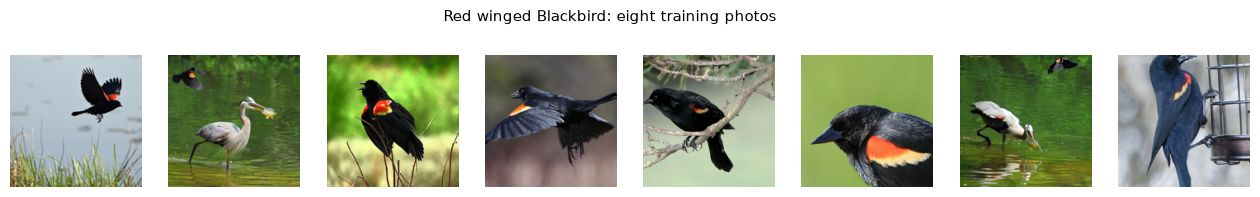

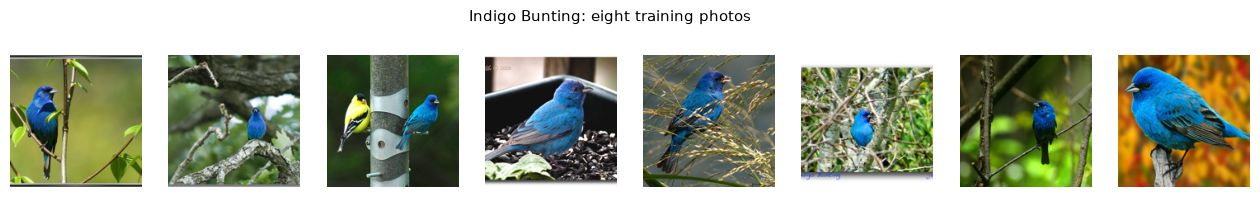

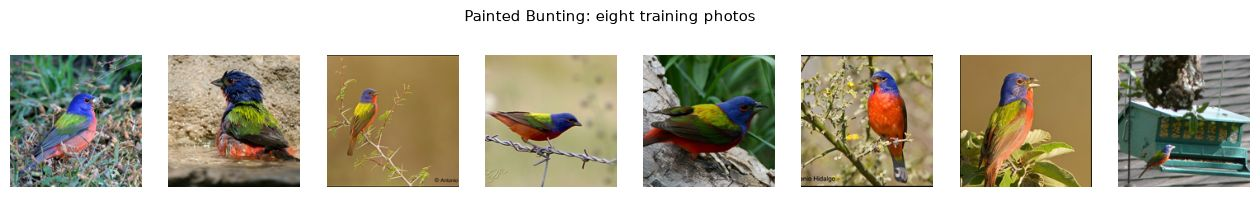

In [10]:
# Draw eight photos of each species
for name in ("Red winged Blackbird", "Indigo Bunting", "Painted Bunting"):
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.3))
    for ax, s in zip(axes, rng.sample(by_label[index[name]], 8)):
        ax.imshow(square(s.path(DATA), 160))
        ax.axis("off")
    fig.suptitle(f"{name}: eight training photos", fontsize=11)
    show_jpeg(fig)

The label names one bird, not the most prominent one. In two of the eight Red-winged Blackbird photos a large wading bird fills the frame and the blackbird is a small dark shape in a corner. The Indigo Bunting photos range from a close-up to a small blue dot in branches, and one also contains an American Goldfinch; that photo is byte-identical to test photo 0273, labeled American Goldfinch (section 5.1). The Painted Bunting photos range from close-ups to a small bird on a feeder. Within one class, then, scale, pose, background and the other birds in the frame all change.

→ **Decision:** RandomResizedCrop at 35–100 % of the area shows each bird at varying scales. Label smoothing (0.1) keeps the model from becoming fully confident on photos where the labeled bird is barely visible.

## 5. Data-quality audit

A test photo that also sits in the training set inflates test accuracy, and a photo that appears twice with two different labels sets an error floor no model can beat. `scripts/prepare_data.py` searched for both and wrote `metadata/audit.json`; this section repeats the search live with the same `birdcls.audit` functions and checks that it finds the same groups.

### 5.1 Byte-identical files

7 groups of byte-identical files among 6,033 photos (audit.json: {'groups': 7, 'train_test_groups': 4, 'label_conflicts': 7})


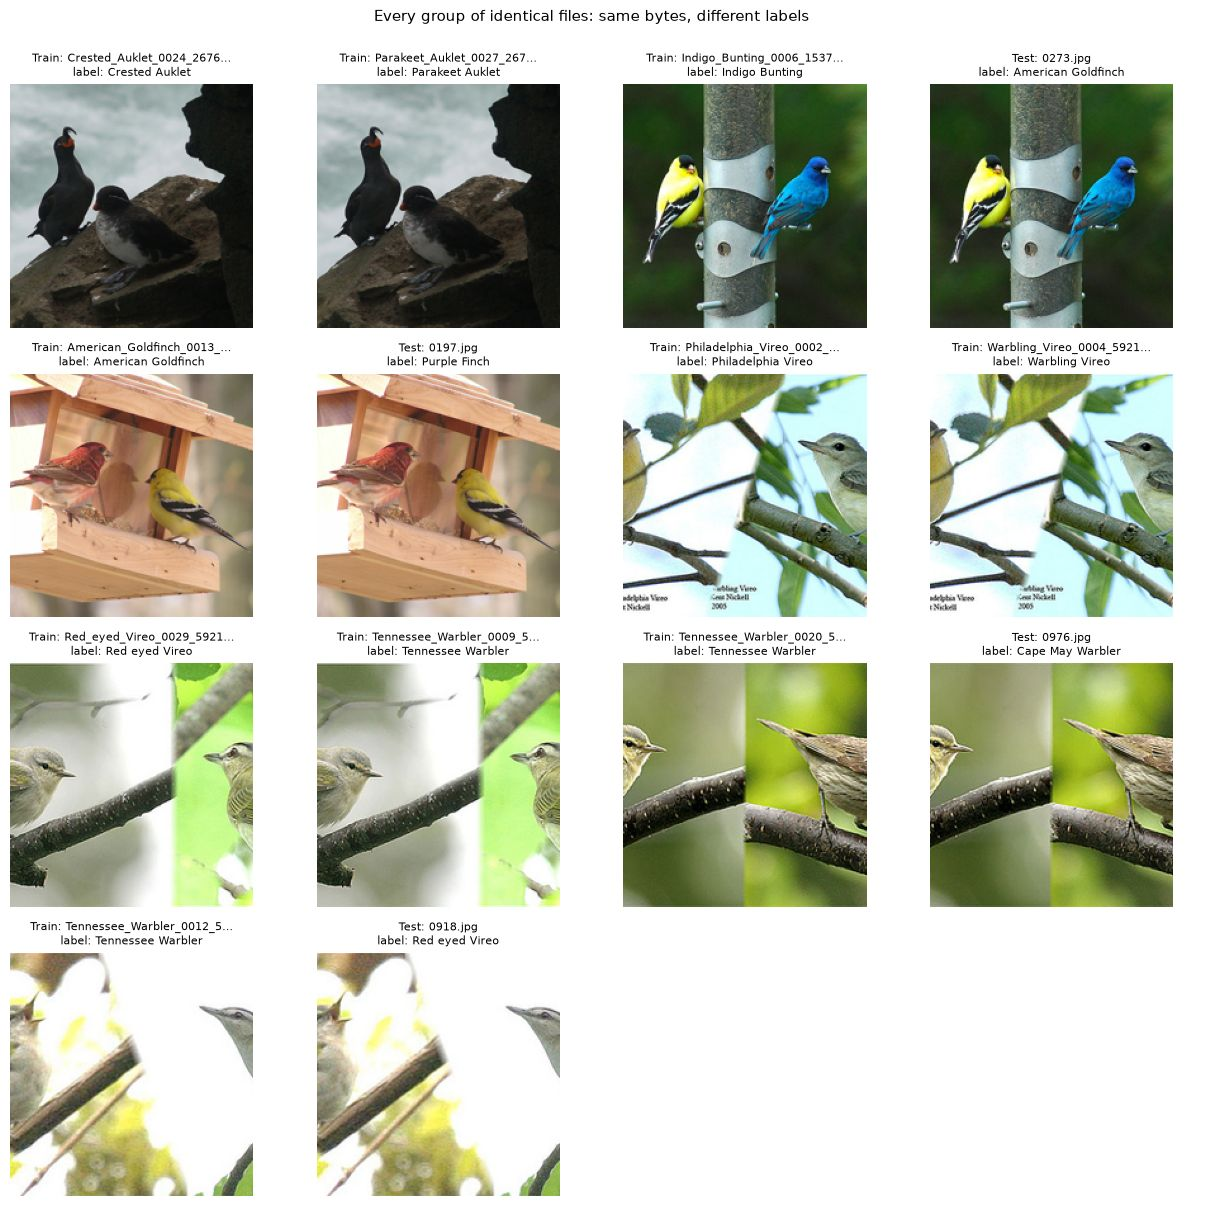

In [11]:
# Find byte-identical files
paths = [s.path(DATA) for s in samples]
digests = [file_md5(p) for p in paths]
exact = group_exact_duplicates(digests)
assert len(exact) == audit["exact_duplicates"]["summary"]["groups"]
print(f"{len(exact)} groups of byte-identical files among {len(samples):,} photos (audit.json: "
      f"{audit['exact_duplicates']['summary']})")

# Lay out two pairs per row
assert max(map(len, exact)) == 2, "the layout below shows pairs"
rows = (len(exact) + 1) // 2
fig, axes = plt.subplots(rows, 4, figsize=(12.4, 3.0 * rows))

# Hide axes
for ax in axes.flat:
    ax.axis("off")

# Draw the two copies of each pair
for k, group in enumerate(exact):
    for ax, i in zip(axes.flat[2 * k: 2 * k + 2], group):
        s = samples[i]
        name = s.filename if s.split == "Test" else s.filename[:24] + "…"
        ax.imshow(square(s.path(DATA), 192))
        ax.set_title(f"{s.split}: {name}\nlabel: {classes[s.label]}", fontsize=8)

# Add title and show
fig.suptitle("Every group of identical files: same bytes, different labels", y=1.0)
fig.tight_layout()
show_jpeg(fig)

All seven groups are pairs, and every one shows two species in one frame: a goldfinch and a bunting at a feeder, a purple finch and a goldfinch at a feeder, two auklets on a rock, a field-guide plate of Philadelphia and Warbling Vireo side by side, and collages of two warblers or a vireo and a warbler. Each copy is labeled with a different one of the two birds, so neither label is wrong, but the photo is ambiguous. Three pairs lie inside `train.txt` (Crested/Parakeet Auklet, Philadelphia/Warbling Vireo, Red-eyed Vireo/Tennessee Warbler). Four put a training photo into `test.txt` under the other bird's name (0273, 0197, 0976, 0918). A model that has learned the training copy's label gets the test copy wrong, unless it names the other bird. These four photos set an error floor.

→ **Decision:** the files stay as the assignment provides them. The four test copies are flagged as `exact-conflict` and left out of the clean subset (section 5.4). In training, two labels on one image act as label noise, which label smoothing softens.

### 5.2 Burst shots: near-identical photos (dHash)

A difference hash (`birdcls.audit.dhash`) shrinks a photo to 9 × 8 gray pixels and keeps one bit per neighboring pair: is the left pixel brighter? Re-encoded or slightly shifted copies of a photo differ in a few of the 64 bits, unrelated photos in about half of them. Hashing all photos needs a full decode, about half a minute.

43 pairs of different files within 6 bits, as in audit.json; 19 of them pair a test photo with a training photo


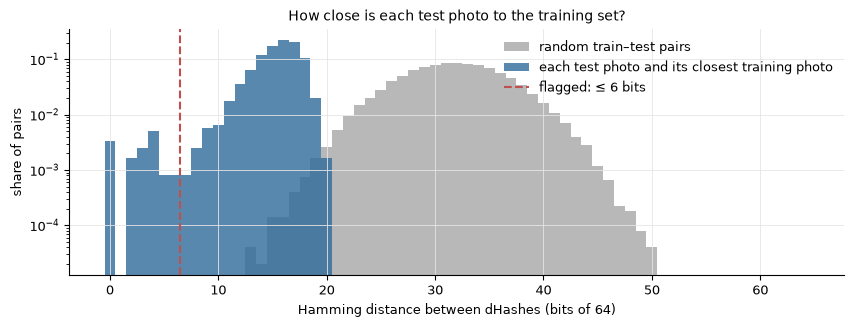

17 test photos lie within 6 bits of a training photo; the median test photo is 16 bits from its closest one


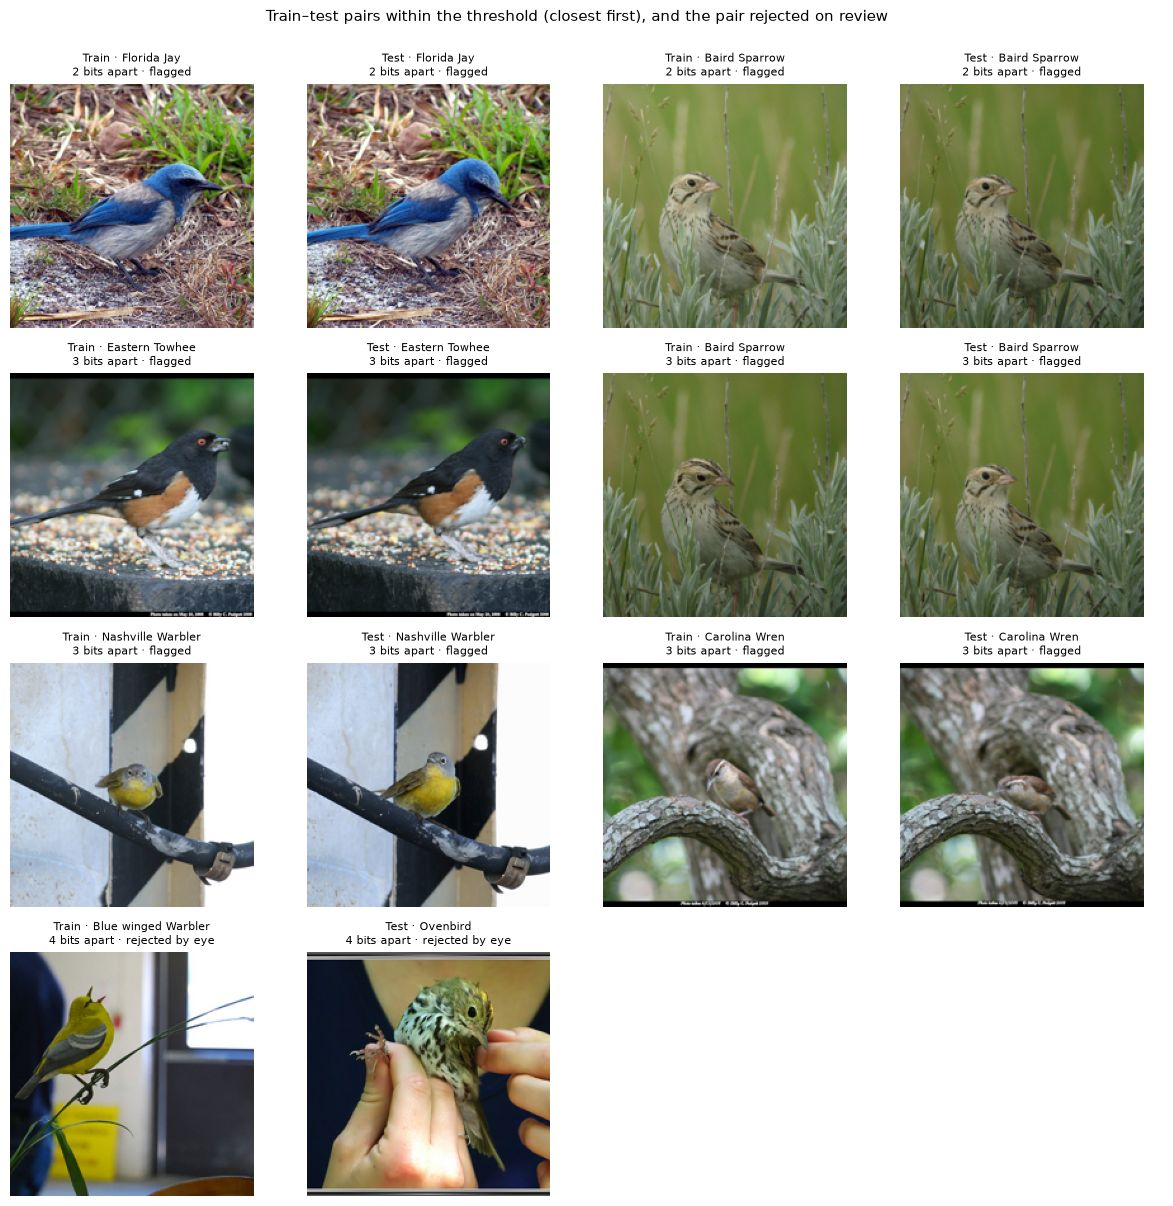

In [12]:
# Get the difference hash of a photo
def photo_dhash(path: Path) -> int:
    with Image.open(path) as im:
        return dhash(im)


# Hash every photo and find near-duplicate pairs
hashes = np.array([photo_dhash(p) for p in paths], dtype=np.uint64)
max_bits = audit["near_duplicates"]["max_dhash_bits"]
group_id = {i: g for g, members in enumerate(exact) for i in members}
# Byte-identical copies are already counted in 5.1, so the audit leaves them out of the near-duplicate pairs.
pairs = [(i, j, d) for i, j, d in near_duplicate_pairs(hashes, max_bits)
         if not (i in group_id and group_id[i] == group_id.get(j))]
assert len(pairs) == len(audit["near_duplicates"]["pairs"])
print(f"{len(pairs)} pairs of different files within {max_bits} bits, as in audit.json; "
      f"{sum(samples[i].split != samples[j].split for i, j, _ in pairs)} of them pair a test photo with a training photo")

# Get each test photo's distance to the training set
is_test = np.array([s.split == "Test" for s in samples])
bits = np.bitwise_count(hashes[is_test][:, None] ^ hashes[~is_test][None, :])  # [test, train] Hamming distances
nearest = bits.min(axis=1)
random_bits = bits.ravel()[np.random.default_rng(SEED).choice(bits.size, 50_000, replace=False)]

# Draw distance histograms
fig, ax = plt.subplots(figsize=(10, 3.2))
edges = np.arange(-0.5, 65)
ax.hist(random_bits, bins=edges, density=True, color=GRAY, alpha=0.7, label="random train–test pairs")
ax.hist(nearest, bins=edges, density=True, color=FIT, alpha=0.8, label="each test photo and its closest training photo")
ax.axvline(max_bits + 0.5, color=ACCENT, linestyle="--", label=f"flagged: ≤ {max_bits} bits")
ax.set(xlabel="Hamming distance between dHashes (bits of 64)", ylabel="share of pairs", yscale="log",
       title="How close is each test photo to the training set?")
ax.legend()
plt.show()

# Print summary
print(f"{np.sum(nearest <= max_bits)} test photos lie within {max_bits} bits of a training photo; "
      f"the median test photo is {np.median(nearest):.0f} bits from its closest one")

# Pick the closest pairs and the rejected one
review = json.loads((META / "dedup_review.json").read_text())
rejected = {frozenset(p) for p in review["false_positive_pairs"]}
cross = sorted((p for p in pairs if samples[p[0]].split != samples[p[1]].split), key=lambda p: p[2])
shown = cross[:6] + [p for p in cross if frozenset((samples[p[0]].filename, samples[p[1]].filename)) in rejected]

# Draw the pairs
fig, axes = plt.subplots((len(shown) + 1) // 2, 4, figsize=(12, 3.0 * ((len(shown) + 1) // 2)), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for k, (i, j, d) in enumerate(shown):
    verdict = "rejected by eye" if frozenset((samples[i].filename, samples[j].filename)) in rejected else "flagged"
    for ax, idx in zip(axes.flat[2 * k: 2 * k + 2], (i, j)):
        s = samples[idx]
        ax.imshow(square(s.path(DATA), 192))
        ax.set_title(f"{s.split} · {classes[s.label]}\n{d} bits apart · {verdict}", fontsize=8)

# Add title and show
fig.suptitle("Train–test pairs within the threshold (closest first), and the pair rejected on review", y=1.0)
fig.tight_layout()
show_jpeg(fig)

Excluding the byte-identical copies, 43 pairs of photos lie within 6 bits, and 19 of them pair a test photo with a training photo. A test photo's closest training photo is typically 16 bits away and a random pair about 32. Very few test photos fall between 7 and 10 bits, so the 6-bit threshold sits in a gap of the distribution. The flagged pairs are either the same photo re-cropped or re-encoded (Florida Jay, Nashville Warbler) or consecutive frames of a burst (Carolina Wren, Baird's Sparrow). One pair at 4 bits shows two different photos, a Blue-winged Warbler and an Ovenbird, whose coarse brightness layout happens to match. The review rejected it (`metadata/dedup_review.json`). dHash compares only a 9 × 8 brightness pattern, so its matches need that check.

The 17 test photos within 6 bits are the 4 exact conflicts, 12 burst shots with the same label as their training twin, and the rejected Ovenbird.

→ **Decision:** the 12 burst shots are flagged as `near-same-label`. They are easier than a genuinely new photo, so they are left out of the clean subset.

### 5.3 Same-session photos (embedding similarity)

dHash misses a second photo of the same bird on the same perch when the bird has moved. `scripts/audit_embeddings.py` found those with a frozen DINOv3 ViT-L: the cosine similarity of each test photo to its nearest training photo. The threshold was set by looking at the pairs (`metadata/dedup_review.json`).

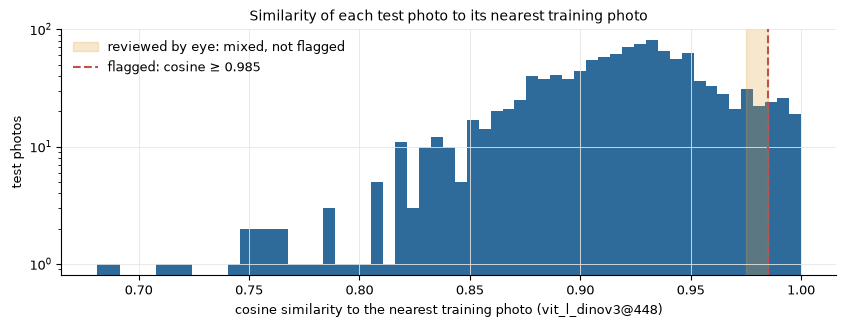

63 test photos at cosine ≥ 0.985; 59 of them share their neighbor's label


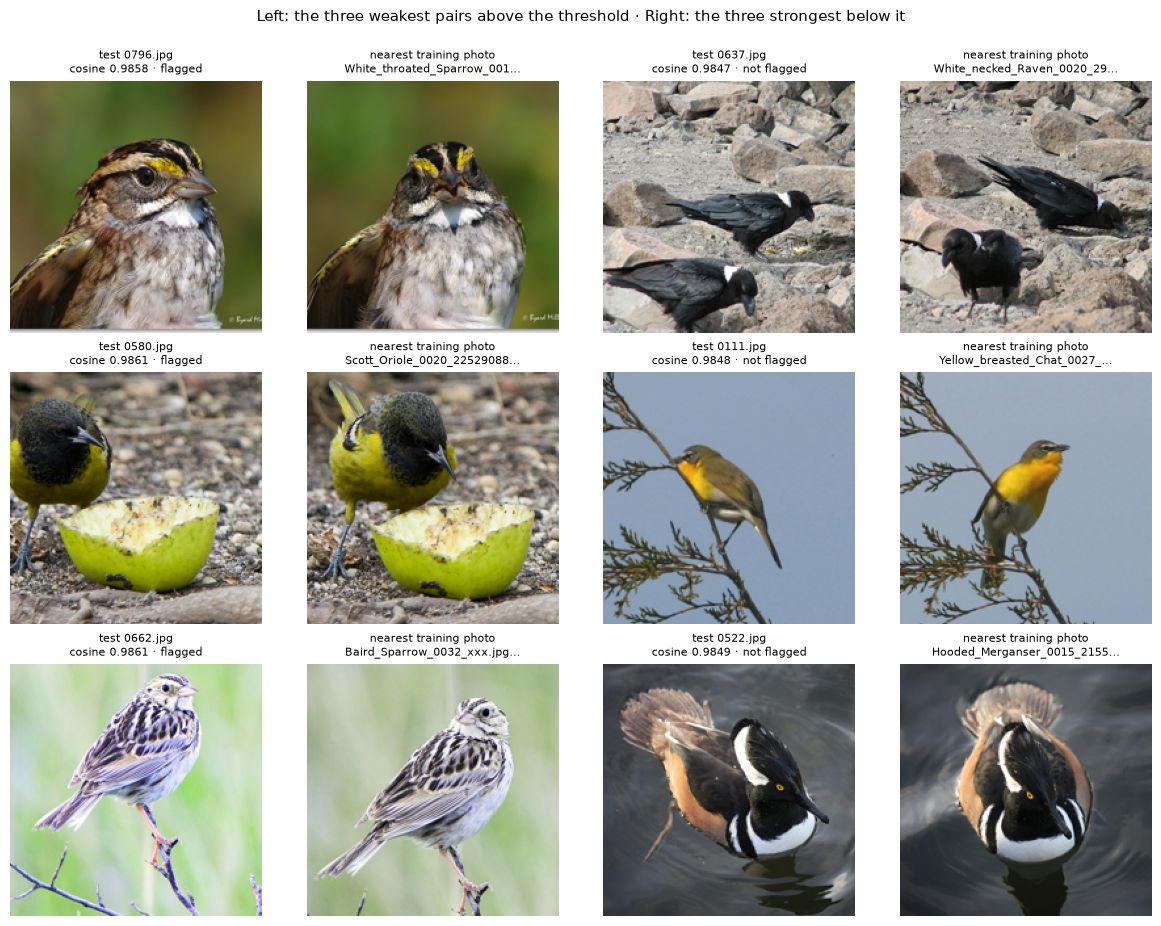

In [13]:
# Load the embedding audit
embedding = json.loads((META / "embedding_audit.json").read_text())
threshold = review["same_session_threshold"]
cosine = np.array([r["cosine"] for r in embedding["test"]])

# Draw similarity histogram
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(cosine, bins=np.linspace(cosine.min(), 1, 60), color=FIT)
ax.axvspan(0.975, threshold, color=VAL, alpha=0.25, label="reviewed by eye: mixed, not flagged")
ax.axvline(threshold, color=ACCENT, linestyle="--", label=f"flagged: cosine ≥ {threshold}")
ax.set(xlabel=f"cosine similarity to the nearest training photo ({embedding['features']})", ylabel="test photos",
       yscale="log", title="Similarity of each test photo to its nearest training photo")
ax.legend(loc="upper left")
plt.show()

# Pick pairs on both sides of the threshold
dhash_flagged = {samples[i].filename if samples[i].split == "Test" else samples[j].filename
                 for i, j, _ in cross}
rows = sorted(embedding["test"], key=lambda r: r["cosine"])
above = [r for r in rows if r["cosine"] >= threshold and r["file"] not in dhash_flagged][:3]
below = [r for r in rows if 0.975 <= r["cosine"] < threshold][-3:]

# Print flagged count
print(f"{np.sum(cosine >= threshold)} test photos at cosine ≥ {threshold}; "
      f"{sum(r['same_label'] for r in embedding['test'] if r['cosine'] >= threshold)} of them share their neighbor's label")

# Draw the pairs
fig, axes = plt.subplots(3, 4, figsize=(12, 9.2))
for row_axes, pair_rows, tag in ((axes[:, :2], above, "flagged"), (axes[:, 2:], below, "not flagged")):
    for (ax_test, ax_train), r in zip(row_axes, pair_rows):
        ax_test.imshow(square(DATA / "Test" / r["file"], 192))
        ax_test.set_title(f"test {r['file']}\ncosine {r['cosine']:.4f} · {tag}", fontsize=8)
        ax_train.imshow(square(DATA / "Train" / r["nearest_train"], 192))
        ax_train.set_title(f"nearest training photo\n{r['nearest_train'][:26]}…", fontsize=8)

# Hide axes, add title and show
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Left: the three weakest pairs above the threshold · Right: the three strongest below it", y=1.0)
fig.tight_layout()
show_jpeg(fig)

63 test photos have a training photo at cosine similarity 0.985 or higher; 59 of them share its label, and the other 4 are the exact conflicts. Above the threshold the pairs are the same bird at the same place in a different pose: the White-throated Sparrow turns its head, and the Scott's Oriole moves at the same piece of fruit. Two of the three strongest pairs just below the threshold are visibly the same scene too (two White-necked Ravens on the same rocks, a Yellow-breasted Chat on the same branch), and the third, a Hooded Merganser on dark water, probably is. The band from 0.975 to 0.985 mixes such same-session pairs with photos that are merely similar, so no threshold separates them cleanly. The chosen threshold is conservative: the flagged set is a lower bound on the train–test overlap.

→ **Decision:** the 47 photos above the threshold that sections 5.1 and 5.2 had not already flagged are flagged as `same-session`. The clean subset is therefore cleaner than the full test set, but not free of same-session photos.

### 5.4 The clean test subset

The official test set is never modified. `flagged_test_images` collects the flagged photos so accuracy can also be reported on the rest, the *clean* subset, which shows how much the duplicates move the numbers.

In [14]:
# Get flagged test photos
flags = flagged_test_images(META)
md_table(["reason", "test photos"], [[reason, n] for reason, n in Counter(flags.values()).most_common()])

# Print clean subset size
clean = len(test) - len(flags)
print(f"clean test subset: {clean:,} of {len(test):,} photos ({len(flags)} flagged)")

| reason | test photos |
|---|---|
| same-session | 47 |
| near-same-label | 12 |
| exact-conflict | 4 |

clean test subset: 1,141 of 1,204 photos (63 flagged)


63 test photos (5.2 %) are flagged, leaving 1,141 clean ones. The flags pull in opposite directions. The 59 near-copies with the same label make the test easier: Notebook 2 (section 9.7) finds the final model right on all 59. The 4 exact conflicts make it harder: the model is right on 1 of them. Because the two effects partly cancel and the flagged photos are only 5 % of the test set, clean accuracy (96.7 %) differs from the full test accuracy (96.6 %) by 0.1 pp.

→ **Decision:** every model in Notebook 2 and in the report is scored on both the full test set and the clean subset.

## 6. Preprocessing, augmentation and the data loader

The final model's settings are read from its training run, and the normalization constants from the backbone's pretraining configuration, so every picture below is produced by exactly the transforms used in training.

In [15]:
# Load the training config and transforms
cfg = TrainConfig(**json.loads((RUN_LOGS / FINAL_RUN / "config.json").read_text()))
eval_tf = build_eval_transform(cfg.img_size, MEAN, STD, cfg.eval_crop_pct)
train_tf = build_train_transform(cfg.img_size, MEAN, STD, cfg.rrc_scale_min, cfg.augment, cfg.random_erasing)

# Print settings
print(f"input {cfg.img_size} px · RandomResizedCrop scale ≥ {cfg.rrc_scale_min} · {cfg.augment} · "
      f"random erasing p = {cfg.random_erasing} · batch {cfg.batch_size} × {cfg.accum_steps} accumulation steps")
print("\nevaluation transform:", eval_tf, "\ntraining transform:", train_tf, sep="\n")

# Get normalization tensors
MEAN_T, STD_T = torch.tensor(MEAN)[:, None, None], torch.tensor(STD)[:, None, None]


def to_image(x: torch.Tensor) -> np.ndarray:
    """Undo Normalize so a network input can be displayed."""
    return (x * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()

input 448 px · RandomResizedCrop scale ≥ 0.35 · trivialaugment · random erasing p = 0.25 · batch 16 × 4 accumulation steps

evaluation transform:
Compose(
    Resize(size=448, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(448, 448))
    ToTensor()
    Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711])
)

training transform:
Compose(
    RandomResizedCrop(size=(448, 448), scale=(0.35, 1.0), ratio=(0.75, 1.3333), interpolation=bicubic, antialias=True)
    RandomHorizontalFlip(p=0.5)
    TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.BILINEAR, fill=None)
    ToTensor()
    Normalize(mean=[0.48145466, 0.4578275, 0.40821073], std=[0.26862954, 0.26130258, 0.27577711])
    RandomErasing(p=0.25, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=random, inplace=False)
)


### 6.1 The evaluation transform, step by step

Validation and test photos, and the web app's uploads, go through a fixed transform: resize the short side to 448 px, cut the central 448 × 448 square, convert to a tensor and normalize. The cell builds the steps one at a time and checks that together they equal `build_eval_transform`.

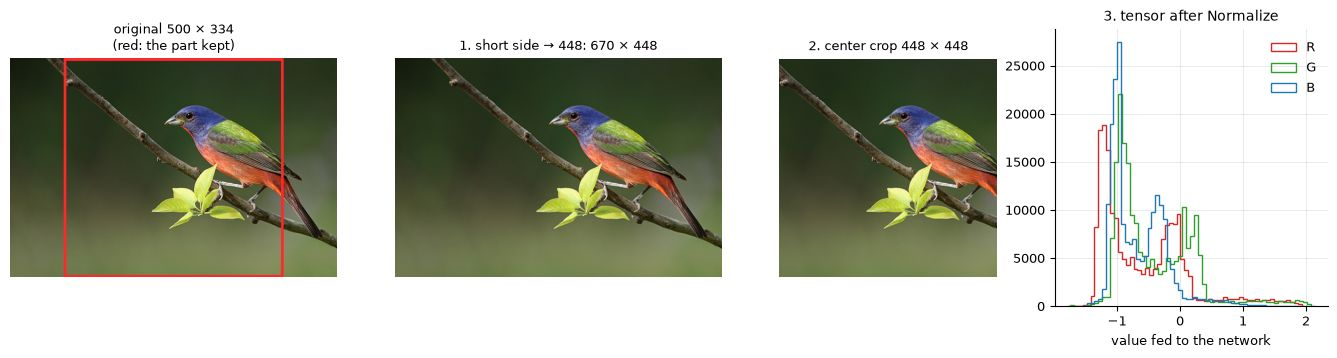

Painted_Bunting_0006_2862481106.jpg: tensor (3, 448, 448) torch.float32; per-channel mean [-0.57, -0.41, -0.67], std [0.69, 0.63, 0.44]


In [16]:
# Pick a wide photo
size_of = {s.filename: tuple(sz) for s, sz in zip(samples, sizes.tolist())}
demo = next(s for s in sorted(train, key=lambda s: s.filename)
            if classes[s.label] == "Painted Bunting" and size_of[s.filename][0] / size_of[s.filename][1] > 1.4)
with Image.open(demo.path(DATA)) as im:
    photo = im.convert("RGB")

# Apply the evaluation steps one by one
resize = T.Resize(round(cfg.img_size / cfg.eval_crop_pct), interpolation=T.InterpolationMode.BICUBIC)
crop = T.CenterCrop(cfg.img_size)
resized = resize(photo)
cropped = crop(resized)
x = T.Normalize(MEAN, STD)(T.ToTensor()(cropped))
assert torch.allclose(x, eval_tf(photo)), "the steps must reproduce build_eval_transform"

# Outline the kept part
scale = resized.width / photo.width
left, top = (resized.width - cfg.img_size) / 2 / scale, (resized.height - cfg.img_size) / 2 / scale
outlined = photo.copy()
ImageDraw.Draw(outlined).rectangle([left, top, left + cfg.img_size / scale, top + cfg.img_size / scale],
                                   outline=(255, 40, 40), width=4)

# Draw each step
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw={"width_ratios": [1.5, 1.5, 1, 1.25]})
for ax, image, title in ((axes[0], outlined, f"original {photo.width} × {photo.height}\n(red: the part kept)"),
                         (axes[1], resized, f"1. short side → {resized.height}: {resized.width} × {resized.height}"),
                         (axes[2], cropped, f"2. center crop {cfg.img_size} × {cfg.img_size}")):
    ax.imshow(image)
    ax.set_title(title, fontsize=9)
    ax.axis("off")

# Draw channel histograms
for channel, color, name in zip(x, ("#d62728", "#2ca02c", "#1f77b4"), "RGB"):
    axes[3].hist(channel.ravel().numpy(), bins=60, histtype="step", color=color, label=name)
axes[3].set(title="3. tensor after Normalize", xlabel="value fed to the network")
axes[3].legend()
show_jpeg(fig)

# Print tensor statistics
print(f"{demo.filename}: tensor {tuple(x.shape)} {x.dtype}; per-channel mean "
      f"{[round(v, 2) for v in x.mean((1, 2)).tolist()]}, std {[round(v, 2) for v in x.std((1, 2)).tolist()]}")

The demo photo is a wide landscape shot. Resizing keeps the aspect ratio (short side to 448 px), and the center crop then cuts the sides: here the Painted Bunting loses its tail. After normalization the values span roughly −2 to +2. This photo's channel means are negative because its dark green background is darker than the average photo.

→ **Decision:** the same transform serves validation, test and the web app, so all three see identical inputs. Padding photos to a square would keep the tail, but it would shrink the bird and add borders the pretraining never saw; it was not tested.

### 6.2 Each training augmentation on its own

The training transform chains four random operations. Below, each one is applied alone to the same photo, eight times. Random erasing is shown with probability 1 so every draw shows a patch; in training it fires on a quarter of the photos.

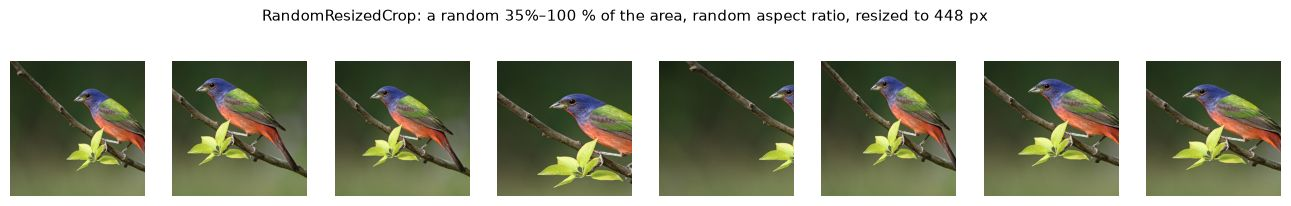

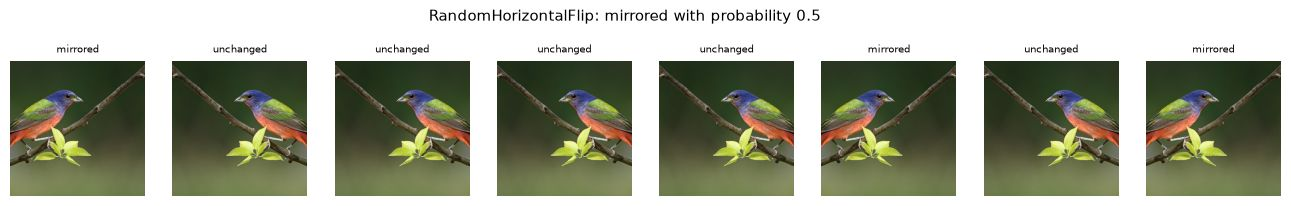

TrivialAugmentWide picks one of 14 operations per photo: Identity, ShearX, ShearY, TranslateX, TranslateY, Rotate, Brightness, Color, Contrast, Sharpness, Posterize, Solarize, AutoContrast, Equalize


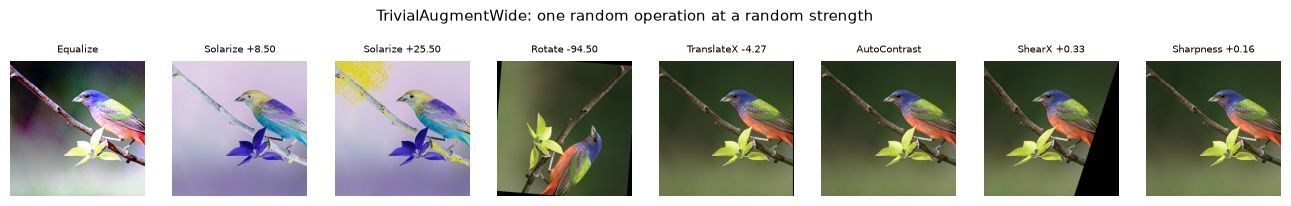

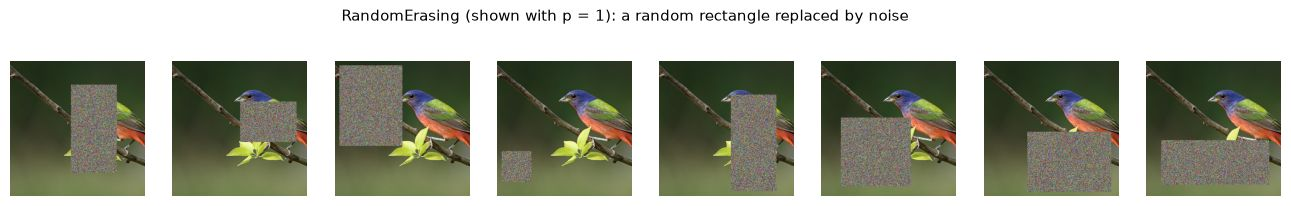

In [17]:
# Draw a row of images with titles
def row_of(images: list, titles: list[str], suptitle: str) -> None:
    fig, axes = plt.subplots(1, len(images), figsize=(2.05 * len(images), 2.45))
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=7.5)
        ax.axis("off")
    fig.suptitle(suptitle, fontsize=10.5)
    show_jpeg(fig)


# Show random crops
rrc = T.RandomResizedCrop(cfg.img_size, scale=(cfg.rrc_scale_min, 1.0), interpolation=T.InterpolationMode.BICUBIC)
row_of([rrc(photo) for _ in range(8)], [""] * 8,
       f"RandomResizedCrop: a random {cfg.rrc_scale_min:.0%}–100 % of the area, random aspect ratio, resized to {cfg.img_size} px")

# Show flips
flip = T.RandomHorizontalFlip()
flips = [flip(cropped) for _ in range(8)]
row_of(flips, ["mirrored" if np.array_equal(np.asarray(f), np.asarray(cropped)[:, ::-1]) else "unchanged"
               for f in flips], "RandomHorizontalFlip: mirrored with probability 0.5")

# List TrivialAugment operations
trivial = T.TrivialAugmentWide(interpolation=T.InterpolationMode.BILINEAR)
space = trivial._augmentation_space(trivial.num_magnitude_bins)
print(f"TrivialAugmentWide picks one of {len(space)} operations per photo: {', '.join(space)}")


def trivial_augment_named(image: Image.Image) -> tuple[Image.Image, str]:
    """One TrivialAugmentWide draw made exactly as its forward() makes it, but also returning the op chosen."""
    name = list(space)[int(torch.randint(len(space), (1,)))]
    magnitudes, signed = space[name]
    magnitude = float(magnitudes[int(torch.randint(len(magnitudes), (1,)))]) if magnitudes.ndim > 0 else 0.0
    if signed and torch.randint(2, (1,)):
        magnitude *= -1.0
    out = autoaugment._apply_op(image, name, magnitude, interpolation=trivial.interpolation, fill=None)
    return out, f"{name} {magnitude:+.2f}" if magnitudes.ndim > 0 else name


# Show TrivialAugment draws
draws = [trivial_augment_named(cropped) for _ in range(8)]
row_of([d[0] for d in draws], [d[1] for d in draws], "TrivialAugmentWide: one random operation at a random strength")

# Show random erasing
erase = T.RandomErasing(p=1.0, value="random")
row_of([to_image(erase(x.clone())) for _ in range(8)], [""] * 8,
       "RandomErasing (shown with p = 1): a random rectangle replaced by noise")

Each operation is a bet that it changes the photo without changing the species:
- **RandomResizedCrop** shows the bird at other scales and positions. At the lower bound of 35 % of the area, the crop can cut off most of the bird; section 6.3 shows draws that lose it entirely.
- **Horizontal flip** is safe because a mirrored bird is the same species. The same symmetry justifies averaging each prediction over the photo and its mirror at test time (Notebook 2, section 9.3).
- **TrivialAugment** picks one of 14 operations at a random strength. Its color operations (Color, Solarize, Posterize) can change the plumage color that defines a species, but each fires on about 1 photo in 14, and one of the 14 options is Identity.
- **Random erasing** hides a patch, sometimes the head, which forces the network to use more than one cue.

→ **Decision:** moderate settings. The crop's lower bound is 35 % rather than the ImageNet default of 8 %, because in photos where the bird is small, a crop of 8 % of the area would often contain no bird. In the ablation study (Notebook 2, section 8.6), removing TrivialAugment, random erasing or both together with the other regularizers changes val accuracy by less than 2σ of seed noise. On this backbone the augmentations are cheap insurance rather than the source of the accuracy.

### 6.3 The full training pipeline

What the network actually receives: sixteen draws of the complete `build_train_transform` on the same photo, converted back from normalized tensors for display. Over 20 epochs the network sees each training photo twenty times, each time in a different version like these.

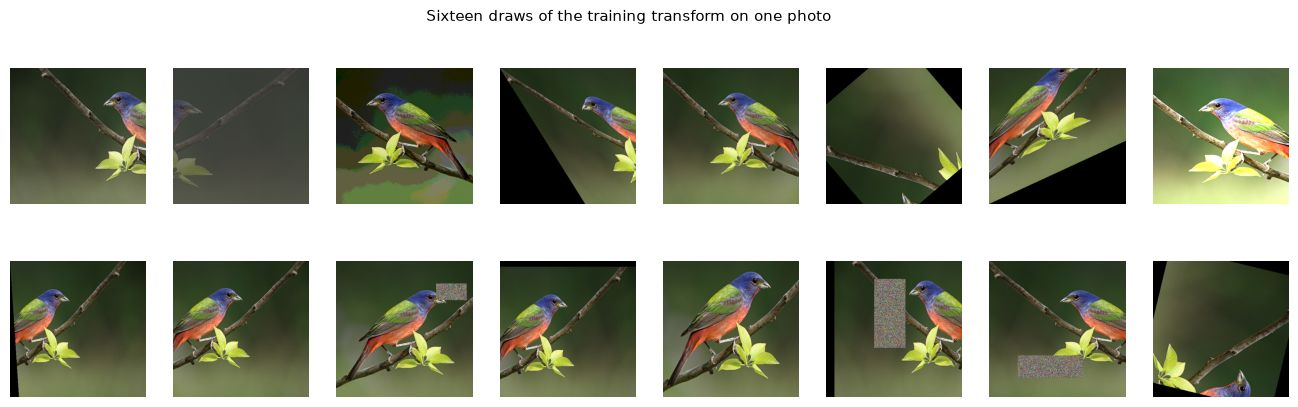

In [18]:
# Draw 16 training transforms of one photo
fig, axes = plt.subplots(2, 8, figsize=(16.5, 4.6))
for ax in axes.flat:
    ax.imshow(to_image(train_tf(photo)))
    ax.axis("off")
fig.suptitle("Sixteen draws of the training transform on one photo", fontsize=11)
show_jpeg(fig)

### 6.4 A real batch from the data loader

`BirdDataset` decodes a photo, converts it to RGB and applies the transform; PyTorch's `DataLoader` shuffles the fit split and stacks 16 photos into one tensor. Training adds the gradients of 4 such batches before each optimizer step, an effective batch of 64, because 16 photos at 448 px are what fits in the T4 GPU's memory.

images (16, 3, 448, 448) torch.float32 · labels (16,) torch.int64 · dataset indices [3053, 1188, 433, 3417]…
batch mean per channel [0.02, 0.19, 0.26], std [0.97, 1.02, 1.13]
expected from the CUB statistics of section 3.2 (before augmentation): mean [-0.01, 0.14, 0.07], std [0.85, 0.85, 0.95]


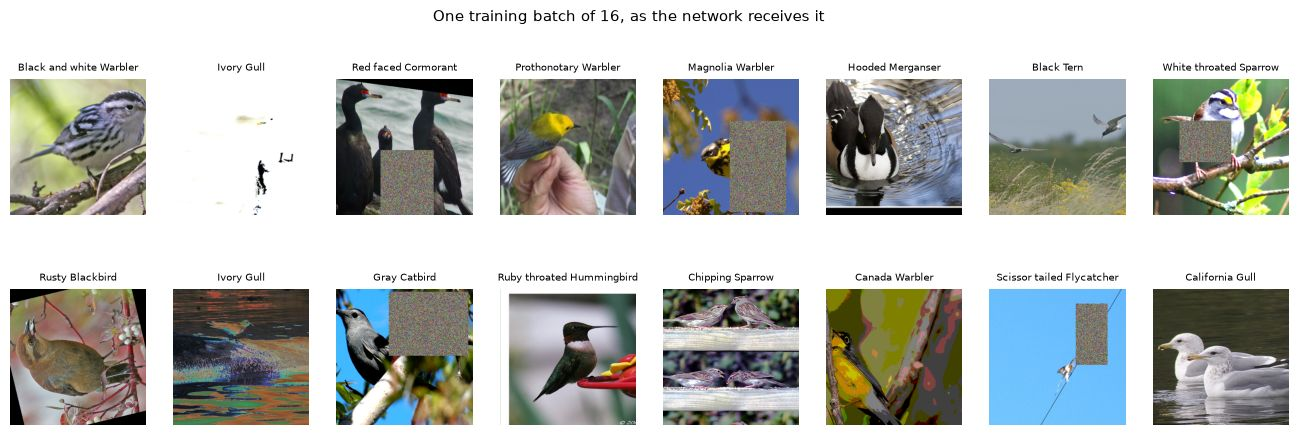

In [19]:
# Load one training batch
loader = DataLoader(BirdDataset(DATA, fit, train_tf), batch_size=cfg.batch_size, shuffle=True, num_workers=0,
                    generator=torch.Generator().manual_seed(SEED))
xb, yb, ib = next(iter(loader))

# Print shapes and statistics
print(f"images {tuple(xb.shape)} {xb.dtype} · labels {tuple(yb.shape)} {yb.dtype} · dataset indices {ib[:4].tolist()}…")
print(f"batch mean per channel {[round(v, 2) for v in xb.mean((0, 2, 3)).tolist()]}, "
      f"std {[round(v, 2) for v in xb.std((0, 2, 3)).tolist()]}")
expected_mean = (data_mean - np.array(MEAN)) / np.array(STD)
print(f"expected from the CUB statistics of section 3.2 (before augmentation): mean "
      f"{[round(v, 2) for v in expected_mean.tolist()]}, std {[round(v, 2) for v in (data_std / np.array(STD)).tolist()]}")

# Draw the batch
fig, axes = plt.subplots(2, 8, figsize=(16.5, 5.0))
for ax, image, label in zip(axes.flat, xb, yb):
    ax.imshow(to_image(image))
    ax.set_title(classes[int(label)], fontsize=7.5)
    ax.axis("off")
fig.suptitle(f"One training batch of {cfg.batch_size}, as the network receives it", fontsize=11)
show_jpeg(fig)

### 6.5 RandAugment against TrivialAugment

The ablation study (Notebook 2, section 8.6) swaps TrivialAugment for RandAugment, which applies two operations at a fixed strength of 9 (of 31) instead of one at a random strength.

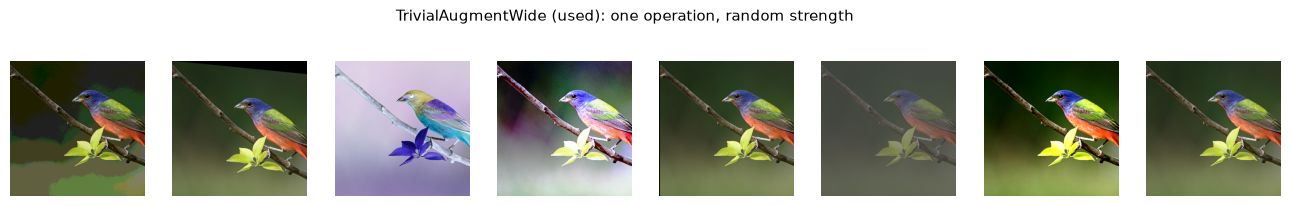

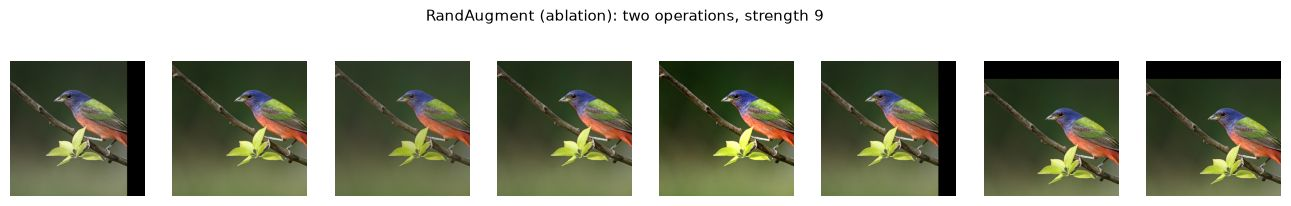

In [20]:
# Compare TrivialAugment and RandAugment
rand = T.RandAugment(num_ops=2, magnitude=9, interpolation=T.InterpolationMode.BILINEAR)
row_of([trivial(cropped) for _ in range(8)], [""] * 8, "TrivialAugmentWide (used): one operation, random strength")
row_of([rand(cropped) for _ in range(8)], [""] * 8, "RandAugment (ablation): two operations, strength 9")

### 6.6 Mixup and CutMix

Another ablation variant mixes pairs of photos: Mixup blends two whole photos, CutMix pastes a rectangle of one into the other, and the label becomes the same mixture of the two species. The cell applies timm's `Mixup`, the class the training loop uses, with the ablation run's settings to the batch above. timm mixes the batch with itself in reverse order, so the first photo is mixed with the last, the second with the second-to-last, and so on.

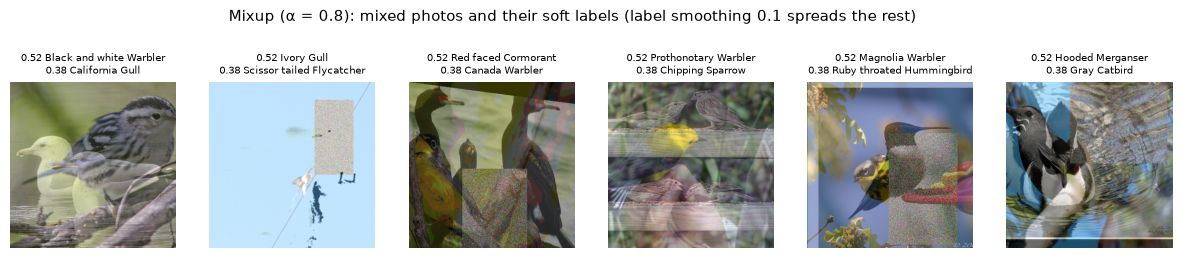

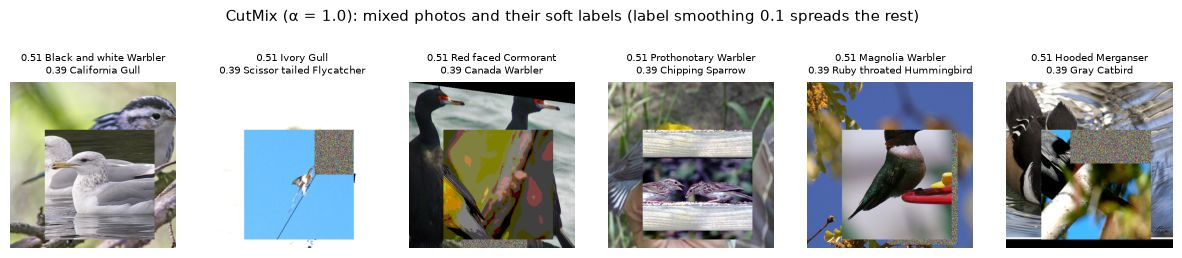

In [21]:
# Load the Mixup and CutMix settings
abl = json.loads((RUN_LOGS / "abl_convnext__mixup_cutmix__s0" / "config.json").read_text())

# Draw mixed photos for each mode
for mode, alphas in (("Mixup", {"mixup_alpha": abl["mixup_alpha"], "cutmix_alpha": 0.0}),
                     ("CutMix", {"mixup_alpha": 0.0, "cutmix_alpha": abl["cutmix_alpha"]})):
    np.random.seed(SEED)  # timm draws the mixing weight with numpy
    mixer = Mixup(**alphas, prob=1.0, label_smoothing=abl["label_smoothing"], num_classes=len(classes))
    mixed, soft = mixer(xb.clone(), yb.clone())

    # Draw each mixed photo with its two labels
    fig, axes = plt.subplots(1, 6, figsize=(15, 3.2))
    for ax, image, target in zip(axes, mixed, soft):
        weight, label = target.topk(2)
        ax.imshow(to_image(image))
        ax.set_title(f"{weight[0]:.2f} {classes[int(label[0])]}\n{weight[1]:.2f} {classes[int(label[1])]}", fontsize=7.5)
        ax.axis("off")

    # Add title and show
    fig.suptitle(f"{mode} (α = {alphas['mixup_alpha'] or alphas['cutmix_alpha']}): mixed photos and their soft labels "
                 f"(label smoothing {abl['label_smoothing']} spreads the rest)", fontsize=10.5)
    show_jpeg(fig)

Mixup produces two semi-transparent birds, which is not a photo anyone would upload. timm draws one mixing weight per batch, so all six photos here share the same weights (0.52 and 0.38, with label smoothing spreading the remaining 0.10). CutMix pastes a rectangle, and its label weight follows the rectangle's area even when the rectangle holds only background. Both blur exactly the small cues (bill color, wing bars) that separate look-alike species.

In the ablation (Notebook 2, section 8.6), adding Mixup/CutMix changed ConvNeXt-L's val accuracy by −0.14 pp (−0.6σ, no measurable effect). It lowered ResNet-50's by 3.8 pp (−5.4σ), even though ResNet-50 overfits badly.

→ **Decision:** Mixup and CutMix are not part of the final recipe.

## Summary: findings and the decisions they drove

| finding | section | decision |
|---|---|---|
| about 19 fit photos per species, 200 species | 2 | transfer learning; 14 pretrained backbones compared with linear probes before any fine-tuning |
| 84 % of species have look-alikes in their group; the cues are small | 1.2, 4.1 | 448 px input; error analysis by group |
| mild imbalance (1.9×); test is a fixed share of each species | 2.1 | no class weights; both required metrics reported |
| about 5 val photos per species: one photo is 0.1 pp | 2.2 | three seeds of the final recipe; ablations read in units of seed noise σ |
| 91 % of photos are enlarged; the center crop discards a median 25 % | 3.1 | short side resized straight to 448 px; flip averaging at test time |
| CUB's color statistics are close to CLIP's | 3.2 | the pretraining normalization is kept |
| the labeled bird is often small, or not the main subject | 1.3, 4.2 | crops of 35–100 % of the area, not 8–100 %; label smoothing 0.1 |
| 4 test photos are copies of training photos with another label; 59 more are near-copies | 5 | test set untouched; a clean subset of 1,141 photos is scored too |
| Mixup and CutMix blur the small cues | 6.6 | not used (no gain in the ablation) |